---
title: "Voorhies' coking law: carbon on catalyst keeps time, not throughput"
description: "The 1945 origin of C_c = A·theta^n, its two printed tables quantified: over a fourfold feed-rate range carbon on catalyst moves with feed rate at an exponent near zero, with standard errors, while carbon on feed moves at about minus one; the printed algebra chain (2)+(3)+(4)->(5) reproduced by two routes; the printed temperature-doubling claim measured per catalyst; and the nomenclature K = A^2 shown inconsistent with the paper's own eq. (8)."
categories: [sec:B, struct:S1, tier:T0, data:tier2, phase:gas-solid]
date: 2026-08-08
---

# Voorhies' coking law: carbon on catalyst keeps time, not throughput

**Catalog ID:** `B2.1` · **Structures:** `S1` · **Tier:** T0

Every deactivation model that writes coke as a function of time-on-stream,
including the Froment–Bischoff reactor model of
[`B2.2`](../B2.2-froment-bischoff-coking/), which was written to replace it,
descends from five pages of *Industrial & Engineering Chemistry*, April 1945:

$$
C_c \;=\; A\,\theta^{\,n},
$$

carbon on catalyst as a power of the time since the catalyst was last
regenerated. The paper's abstract stakes a sharper claim than the power law
itself: *"For all the data examined, the amount of carbon deposited on the
catalyst at given conditions is, within limits, independent of the hydrocarbon
feed rate."* Push twice the oil over the same catalyst for the same two hours
and you get the same carbon on the catalyst, the deposit keeps time, not
throughput.

That is the non-obvious claim, and the paper prints the tables that carry it.
This page quantifies what the printed word "independent" amounts to (a
feed-rate exponent with its standard error, against the competing hypothesis at
exponent $+1$), shows that the paper's two carbon columns are one measurement
seen twice (so the claim gets exactly one test per table, not two), reproduces
the printed conversion–feed-rate–time algebra by two routes, measures the
temperature-doubling claim per catalyst with its standard errors, and settles a
factor-of-two defect in the printed nomenclature of the diffusion hypothesis
from the paper's own two lines.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.09.2"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "B2.1-voorhies-coking-law"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. Packages beyond pymrm and the Colab defaults (numpy, scipy, pandas,
# matplotlib, pyyaml, sympy) are installed here with subprocess, not %pip. The only
# pymrm call on this page is find_roots (see "What pymrm adds").
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Markdown, display
from scipy.integrate import solve_ivp
from scipy.stats import t as student_t
from pymrm.checks import find_roots
from gallery_utils import Claims, cite_data, load_data, load_meta

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
PAGE_B22 = "B2.2-froment-bischoff-coking"


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``. Formats are Python formats, or
    ``pctN`` / ``+pctN`` for a fraction shown as a percentage with N decimals."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        x = v[name]
        mp = re.fullmatch(r"(\+?)pct(\d+)", fmt)
        if mp:
            return f"{x * 100:{mp.group(1)}.{mp.group(2)}f} %"
        return format(x, fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, V=None, **kw):
    """Prose whose numbers are written by code, so they cannot drift. ``V`` is the dictionary
    of the page's numbers; keyword arguments add to it and take precedence."""
    display(Markdown(fill(text, **{**(V or {}), **kw})))


# the printed constants of the paper, read once: every number the text states about them is filled from here
pc = load_data("voorhies-1945-printed-constants.csv", page=PAGE)
K = dict(zip(pc.item_id, pc.printed_value.astype(float)))

## Background

**The source, precisely.** Alexis Voorhies, Jr., "Carbon Formation in
Catalytic Cracking", *Industrial & Engineering Chemistry* **37**(4) 318–322
(April 1945), doi:10.1021/ie50424a010, Esso Laboratories, Standard Oil Company
of New Jersey (Louisiana Division), Baton Rouge, La., identified from the
scan's own display title, by-line and abstract on page 318, with the ACS
download stamp confirming volume 37, issue 4, first page 318. The by-line
prints **"ALEXIS VOORHIES, JR."**; the catalogue's "Voorhies, A." lacks the
Jr., and this page carries it. The scan is CCITT-G4 bilevel at 300 ppi native;
every numeral on this page was read from cropped native-resolution renders at
digit scale, never from the text layer. (The neighbouring `B1.7` Mears file on
disk opens with the tail of another paper discussing "the Voorhies (1945)
relationship", a standing reminder in this repository that a first-page
glance is not an identification.)

**What the paper does.** It observes that for fixed-bed and fluid catalytic
cracking alike, carbon-on-catalyst follows $C_c = A\theta^n$ with $n$ in a
narrow band and $A$ specific to catalyst, feed stock and temperature; that at a
fixed residence time the deposit is nearly independent of feed rate; and it
then chains its two fitted correlations into a working relation between
conversion, feed rate and cracking-period length (its eq. 5), the practical
payoff, "applied to the commercial-scale units". A closing hypothesis reads
the low temperature coefficient as diffusion control through the deposit
itself, predicting $n = 0.5$.

**Where it sits.** Downstream, Froment & Bischoff (1961, page
[`B2.2`](../B2.2-froment-bischoff-coking/)) argue that once coke lays down as
a *profile* along a bed, an activity correlated only with time is ill-posed,
and their Section 7(a) checks their mechanisms against the very exponent range
this paper prints. `B2.2` established which of their mechanism/activity pairs
can reach the Voorhies exponents; that finding is `B2.2`'s and is not restated
here, this page owns the original law, its tables, and its own printed
claims. `B2.3` (Levenspiel's deactivation orders) continues the ladder.

**What this page deliberately does not do.** The fixed-bed carbon-vs-time
points (Fig. 1), the conversion–yield points (Fig. 3), the conversion–time
curves (Fig. 4) and the fluid-cracking data (Fig. 5) exist **only as
figures**. Nothing on this page digitises them: the coefficients and exponents
of eqs. (1), (2), (3), (6), (7) are transcribed as printed and are *not*
refit, and every claim tested here is tested against the paper's **printed
tables and printed equations** alone. In particular, Tables I and II hold
$\theta$ fixed, so **nothing on this page tests the time exponent $n$ against
data**, the page says so rather than pretending otherwise.

## The published model

All equation numbers are the paper's; every constant below was read from a
cropped native-resolution render. The constants as typeset here are compared
with the data file of printed constants by the claim `typeset_constants_match_csv`,
so a retyping error cannot stand.

**The law** (p. 319, unnumbered, then fitted twice):

$$C_c = A\,\theta^{\,n}$$

with, from the Nomenclature (p. 322): $C_c$ = "carbon, weight per cent on
catalyst", $\theta$ = "catalyst residence time, minutes", $A$ = "constant,
depending on catalyst, feed stock, and temperature", and $n$ = "constant,
depending **only slightly** on catalyst, feed stock, temperature" (emphasis
added, that asymmetry is measured below). For fixed-bed cracking $\theta$ is
the length of the process period since the last regeneration.

**The four fitted instances**, as printed:

| eq. | correlation | system | mode |
|---|---|---|---|
| (1) | $C_c = 0.86\,\theta^{0.41}$ | West Texas gas oil, natural (activated clay) catalyst, 850 °F | fixed bed |
| (2) | $C_c = 0.65\,\theta^{0.44}$ | East Texas gas oil, synthetic (silica–alumina) catalyst, 850 °F | fixed bed |
| (6) | $C_c = 0.52\,\theta^{0.38}$ | East Texas gas oil, natural catalyst, 900–930 °F | fluid |
| (7) | $C_c = 0.24\,\theta^{0.53}$ | Tinsley gas oil, synthetic catalyst, 950 °F | fluid |

(Eq. 2 prints its subscript with a filled counter, the ink reads "$C_.$",
but its restatements on pp. 321 and 322 print $C_c$ unambiguously.)

**The carbon-yield correlation** (p. 321), for the same runs as eq. (2):

$$C_f = (3.55)(10^{-5})\,V^{2.93} \tag{3}$$

with $C_f$ = carbon, weight per cent **on feed**, and $V$ = volume per cent
conversion of feed stock, defined on p. 318 as 100 minus volume % cycle gas
oil (400 °F i.b.p.), the paper's own caveat: a correlating convention, "not
an exact measure of feed stock destruction".

**The mass-balance bridge and the derived design equation** (p. 321):

$$C_c = C_f \div (\text{catalyst-to-oil weight ratio})
      = C_f\,U\,\frac{\theta}{60}\,\frac{D_o}{D_c}, \qquad
\frac{D_o}{D_c} = \frac{1}{0.58} \tag{4}$$

$$\therefore\ 0.65\,\theta^{0.44} = (3.55)(10^{-5})\,V^{2.93}\,
   U\,\frac{\theta}{60}\cdot\frac{1}{0.58}
\quad\Longrightarrow\quad
V = 96\cdot\frac{1}{U^{0.34}}\cdot\frac{1}{\theta^{0.19}} \tag{5}$$

where $U$ is feed rate in v/v/hr and $W = U\,D_o/D_c$ (p. 319) converts it to
a weight basis. The chain (2)+(3)+(4)→(5) is pure printed algebra and is
reproduced below, twice: by a symbolic route and by a numeric route with no
solver code in common (they share the one hand isolation step; the printed
triple is the external check on that step).

**The diffusion hypothesis** (p. 322): if the rate of diffusion through the
deposit is inversely proportional to the deposit,

$$\frac{dC_c}{d\theta} = \frac{K}{C_c}
\quad\text{or}\quad
C_c = A\,\theta^{0.5} \tag{8}$$

and the Nomenclature prints "$K$ = constant $(= A^2)$". Integrating the
paper's own left-hand line gives $K = A^2/2$, a factor-of-two defect settled
below, from these two lines alone, and **reported, not repaired**.

**Two studies, kept apart.** The paper's fixed-bed material comes from two
distinct experimental campaigns, and conflating them manufactures a
contradiction: (i) the **Fig.-1 study** behind eqs. (2), (3), (5), small
fixed-bed units, *one* repeatedly regenerated batch of synthetic catalyst of
"such inherent stability that its activity was completely restored after each
successive regeneration", carbon determined from the regeneration gases; and
(ii) the **Table I/II study**, a small-scale fixed-bed unit, a *fresh batch
of catalyst every run*, carbon by combustion of the discharged catalyst.
Same oil, same nominal temperature, different units and batches; the measured
gap between their $A$ values is one of the results below.

## Parameters and assumptions

The law is two constants per system; nothing else enters. Everything this page
computes uses only the printed values, which are read from the data file of
printed constants (the table below is written from it, not typed).

In [3]:
say(r"""| quantity | value | provenance |
|---|---|---|
| $(A, n)$ eq. (1) | <<eq1_A:g>>, <<eq1_n:g>> | p. 319, transcribed (fit to figure-only data; not refit here) |
| $(A, n)$ eq. (2) | <<eq2_A:g>>, <<eq2_n:g>> | p. 319, transcribed (fit to figure-only data; not refit here) |
| eq. (3) | $<<c3_mant:g>>\times10^{-5}$, <<eq3_exp:g>> | p. 321, transcribed (fit to figure-only data; not refit here) |
| $D_o/D_c$ | $1/<<eq4_density_ratio:g>>$ | p. 321, printed once, inside the eq.-(5) derivation only |
| $(A, n)$ eqs. (6), (7) | <<eq6_A:g>>, <<eq6_n:g>> and <<eq7_A:g>>, <<eq7_n:g>> | p. 322, transcribed (fluid; fits to figure-only data) |
| eq. (5) triple | <<eq5_coeff:g>>, <<eq5_expU:g>>, <<eq5_expTheta:g>> | p. 321, printed algebra, re-derived below |
| $\theta$ for Tables I and II | <<theta_tables_min:g>> min | "uniformly maintained at 2 hours", p. 320 |
| the printed doubling claim | <<doubling_low_F:g>> to <<doubling_high_F:g>> °F | p. 320, drawn from Table I through Fig. 2 |
""", c3_mant=K["eq3_coeff"] * 1e5, **K)

| quantity | value | provenance |
|---|---|---|
| $(A, n)$ eq. (1) | 0.86, 0.41 | p. 319, transcribed (fit to figure-only data; not refit here) |
| $(A, n)$ eq. (2) | 0.65, 0.44 | p. 319, transcribed (fit to figure-only data; not refit here) |
| eq. (3) | $3.55\times10^{-5}$, 2.93 | p. 321, transcribed (fit to figure-only data; not refit here) |
| $D_o/D_c$ | $1/0.58$ | p. 321, printed once, inside the eq.-(5) derivation only |
| $(A, n)$ eqs. (6), (7) | 0.52, 0.38 and 0.24, 0.53 | p. 322, transcribed (fluid; fits to figure-only data) |
| eq. (5) triple | 96, 0.34, 0.19 | p. 321, printed algebra, re-derived below |
| $\theta$ for Tables I and II | 120 min | "uniformly maintained at 2 hours", p. 320 |
| the printed doubling claim | 190 to 200 °F | p. 320, drawn from Table I through Fig. 2 |


**Conventions.** Feed-rate exponents are $m \equiv d\ln C/d\ln U$ at fixed
$\theta$ (and nominally fixed $T$), by least squares of $\ln C$ on $\ln U$ on the
printed rows, with the standard error of $m$ from the scatter of those rows;
deviations are (value − printed)/printed. Temperatures stay in °F as printed.
Every fit on this page is stated where it is made: what is fitted to what, over
which rows, and with how many degrees of freedom.

**Assumptions carried from the source.** Carbon means *catalytic* carbon,
strippable carbon is purged before determination (p. 319) and the paper calls
its contribution negligible for these operations. Conversion is the cycle-gas-oil
convention above. Substantially atmospheric pressure ("pressure was not a
variable in the data presented here", p. 319). The feed-rate-independence
claim is bounded by the paper itself: *"It is not proved or claimed that this
observation will hold for all feed stocks, all catalysts, or an extreme
variation in feed rates"* (p. 320). The tables span a limited range of feed
rate, printed with the results below, and every statement lives inside that
span.

## The data

Three datasets, all transcriptions from this paper, read from cropped
native-resolution renders, never the text layer.

### 1. Table I (p. 320): East Texas gas oil, the feed-rate and temperature evidence

Four feed rates × four nominal temperature levels × two catalysts, every run a
fresh 2-hour period on a fresh catalyst batch, carbon by combustion of the
discharged catalyst. This is the paper's own supporting evidence for the
feed-rate claim and the data behind its Fig.-2 temperature claim, so every
test against it below is a **consistency check of the paper's claims with the
paper's own data**, and is labelled so; nothing here is held-out validation.

Two transcription notes, both settled at digit scale: the natural-catalyst
793 °F row and the synthetic 911 °F row print feed rate **1.1** (not 1.0; the
synthetic one was verified twice at 4× magnification after a whole-page read
mis-gave it). The mass-balance identity of results section 2 mildly disfavours the
synthetic 1.1, as computed in the next section, but the glyph is unambiguous,
so 1.1 is transcribed and the tension is reported rather than repaired.

### 2. Table II (p. 320): cetane and Decalin, the widest feed-rate range

Pure-compound cracking, natural catalyst, 850 °F, 2-hour periods, the widest
feed-rate span in the paper, and therefore the sharpest printed test of the
claim.

### 3. The printed constants and prose claims

Every coefficient, exponent and quantitative sentence this page uses, with
locations, in `voorhies-1945-printed-constants.csv`. The five fitted $(A,n)$
pairs and eq. (3) are the author's fits to **figure-only** data; they enter
this page as transcriptions and are never refit.

**Cross-page reconciliation.** `B2.2`'s dataset
`froment-bischoff-1961-printed-claims.csv` carries the Voorhies exponent range
as Froment & Bischoff quote it (their Sec. 7(a)); since this page states the
same range from the original, the two are printed side by side below rather
than retyped. `B2.2`'s findings about those rows, that they are
transcriptions whose OCR mangles the range, and that the quoted range is other
papers' measurements seen through F&B, are inherited and none affects their
use here as a cross-reference.

In [4]:
t1 = load_data("voorhies-1945-tableI.csv", page=PAGE)
t2 = load_data("voorhies-1945-tableII.csv", page=PAGE)
t1_meta = load_meta("voorhies-1945-tableI.csv", page=PAGE)
# the printed text of the carbon cells: it fixes the half-digit rounding allowance of each
t1_str = load_data("voorhies-1945-tableI.csv", page=PAGE, dtype=str)
t2_str = load_data("voorhies-1945-tableII.csv", page=PAGE, dtype=str)

print("Table I (p. 320): fixed-bed, East Texas gas oil, 2-hour periods")
print(t1.to_string(index=False))
print(f"\n{cite_data(t1_meta)}")
print("\nTable II (p. 320): cetane and Decalin, natural catalyst, 850 F, 2-hour periods")
print(t2.to_string(index=False))
print("\nPrinted constants and claims used by this page:")
print(pc[["item_id", "printed_value", "where"]].to_string(index=False))

Table I (p. 320): fixed-bed, East Texas gas oil, 2-hour periods
 catalyst  block  feed_rate_vvhr  temp_F  C_feed_wtpct  C_cat_wtpct
  natural      1             0.6     812           3.8          5.0
  natural      1             0.8     811           2.9          5.1
  natural      1             1.1     793           2.0          4.6
  natural      1             1.2     804           2.0          5.0
  natural      2             0.6     862           4.5          5.7
  natural      2             0.8     848           3.1          5.4
  natural      2             1.0     845           2.5          5.3
  natural      2             1.2     840           2.1          5.4
  natural      3             0.6     911           5.5          6.6
  natural      3             0.8     908           4.3          6.8
  natural      3             1.0     904           3.3          6.7
  natural      3             1.2     904           2.9          6.8
  natural      4             0.6     962           6

In [5]:
# Cross-page reconciliation: the exponent range B2.2 quotes against the original.
fb = load_data("froment-bischoff-1961-printed-claims.csv", page=PAGE_B22)
fb_lo = float(fb.loc[fb.claim_id == "voorhies_n_low", "printed_value"].iloc[0])
fb_hi = float(fb.loc[fb.claim_id == "voorhies_n_high", "printed_value"].iloc[0])
n_printed = {k: K[k] for k in ("eq1_n", "eq2_n", "eq6_n", "eq7_n")}
print("The four gas-oil exponents printed by Voorhies (1945):",
      ", ".join(f"{k[:3]} n = {v:g}" for k, v in n_printed.items()))
print(f"min and max of the four: {min(n_printed.values()):g} and {max(n_printed.values()):g}")
print(f"Froment & Bischoff (1961) Sec. 7(a), as transcribed on B2.2's page: "
      f"'{fb_lo:g} to {fb_hi:g} for gas-oil cracking (Voorhies)'")
same = (min(n_printed.values()) == fb_lo) and (max(n_printed.values()) == fb_hi)
print(f"-> their quoted range is exactly the min and max of the four printed equations: {same}")
assert same, "reconciliation with B2.2's transcription failed: investigate before publishing"

The four gas-oil exponents printed by Voorhies (1945): eq1 n = 0.41, eq2 n = 0.44, eq6 n = 0.38, eq7 n = 0.53
min and max of the four: 0.38 and 0.53
Froment & Bischoff (1961) Sec. 7(a), as transcribed on B2.2's page: '0.38 to 0.53 for gas-oil cracking (Voorhies)'
-> their quoted range is exactly the min and max of the four printed equations: True


## PyMRM implementation

**There is no field to discretise on this page and it would be dishonest to
invent one.** The law is a two-parameter power function; the feed-rate test is
least squares on log-transformed printed rows; the eq.-(5) chain is algebra;
the one differential equation in the paper (eq. 8) is a scalar separable ODE,
integrated symbolically and, as its independent second route, numerically
with `solve_ivp`. No `construct_grad`, no `construct_div`, no Newton solve. The
one pymrm call is `pymrm.checks.find_roots`, which finds the root of the
eq.-(5) chain for the conversion $V$ on the physical range 0 to 100 % and
raises unless it finds exactly one. This page follows
[`A1.6`](../A1.6-wen-yu-minimum-fluidisation/),
[`A1.1`](../A1.1-ergun-pressure-drop/) and
[`F1.4`](../F1.4-krishna-ellenberger-holdup/) in saying so in the section
where a reader would otherwise expect a solver. (The bed that *does* need
operators, coke laying down as a profile along a reactor, is the sequel,
[`B2.2`](../B2.2-froment-bischoff-coking/), which builds exactly that on this
law.)

**One function computes every number.** `study(t1, t2, K)` takes the two printed
tables and the dictionary `K` of printed constants and returns every number the
page publishes, so a break-table row at the end is one more call with one cell or
one constant changed.
The fits it makes are listed after the code.

In [6]:
# The printed text of every carbon cell fixes its half-digit rounding: 4.7 is known to
# +-0.05, 0.75 to +-0.005. These are properties of the print, not of a defect.
def half_ulp(printed):
    """Half of the last printed digit of each cell, from its text."""
    return pd.Series([0.5 * 10.0 ** -(len(s.split(".")[1]) if "." in s else 0)
                      for s in printed], index=printed.index)


HU1, HU2 = half_ulp(t1_str.C_cat_wtpct), half_ulp(t2_str.C_cat_wtpct)
HU_FEED = (half_ulp(t1_str.C_feed_wtpct), half_ulp(t2_str.C_feed_wtpct))

# The fitting tool of the whole page: ordinary least squares with its standard errors.
def ols(X, y):
    """Least squares ``y = X b``: coefficients, their standard errors from the residual
    scatter, and the degrees of freedom."""
    X, y = np.asarray(X, float), np.asarray(y, float)
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    r = y - X @ b
    dof = len(y) - X.shape[1]
    cov = (r @ r / dof) * np.linalg.inv(X.T @ X)
    return b, np.sqrt(np.diag(cov)), dof


def slope_fit(U, C):
    """Feed-rate exponent m = d ln C / d ln U: ln C fitted to ln U with one intercept,
    and the standard error of m from the scatter of the group's own rows."""
    b, se, dof = ols(np.column_stack([np.ones(len(U)), np.log(U)]), np.log(C))
    return float(b[1]), float(se[1]), dof


def slope_endpoints(U, C):
    """The same exponent from the two extreme feed rates only, a regression-free
    estimator that uses the lowest and the highest feed-rate row of the group."""
    U, C = np.asarray(U, float), np.asarray(C, float)
    i, j = int(np.argmin(U)), int(np.argmax(U))
    if (U == U[i]).sum() != 1 or (U == U[j]).sum() != 1:
        raise ValueError("the lowest or highest feed rate occurs in more than one row")
    return float(np.log(C[j] / C[i]) / np.log(U[j] / U[i]))


def slope_rounding_floor(U, C, half):
    """Worst-case shift of the fitted slope when every printed C is off by up to half
    its last printed digit: the linearised ``delta m = sum w_i dlnC_i`` with the least
    squares weights ``w_i``, maximised by the adversarial sign pattern."""
    x = np.log(np.asarray(U, float))
    w = (x - x.mean()) / np.sum((x - x.mean()) ** 2)
    return float(np.sum(np.abs(w) * np.asarray(half, float) / np.asarray(C, float)))


def pooled_slope(df, by, with_T=False):
    """One feed-rate exponent for several groups: ln C_cat fitted to ln U with a separate
    intercept for every group (``by``), and optionally one common temperature slope
    inside the groups, T minus the group's mean T. Returns m, its standard error, dof."""
    lab = df[by].astype(str).agg("|".join, axis=1) if isinstance(by, list) else df[by].astype(str)
    labv = lab.to_numpy(dtype=str)
    Xb = (labv[:, None] == np.unique(labv)[None, :]).astype(float)
    cols = [Xb, np.log(df.feed_rate_vvhr.to_numpy())[:, None]]
    if with_T:
        cols.append((df.temp_F - df.groupby(labv).temp_F.transform("mean")).to_numpy()[:, None])
    b, se, dof = ols(np.hstack(cols), np.log(df.C_cat_wtpct.to_numpy()))
    return float(b[Xb.shape[1]]), float(se[Xb.shape[1]]), dof


def dt2_fit(T, C):
    """Doubling interval ln 2 / s of the carbon, ln C fitted to T (s = d ln C / dT),
    with its standard error ln 2 se(s) / s^2 from the scatter of the rows."""
    b, se, dof = ols(np.column_stack([np.ones(len(T)), np.asarray(T, float)]), np.log(np.asarray(C, float)))
    return float(np.log(2.0) / b[1]), float(np.log(2.0) * se[1] / b[1] ** 2), float(b[1])


def unique_root(f, lo, hi, xtol):
    """The one root of ``f`` on the physical range [lo, hi], by pymrm.checks.find_roots.
    Raises unless it returns exactly one."""
    out = find_roots(f, lo, hi, xtol=xtol)
    if len(out["roots"]) != 1:
        raise ValueError(f"{len(out['roots'])} roots on [{lo:g}, {hi:g}]: {out['message']}")
    return float(out["roots"][0])


def last_digit(x):
    """One unit of the last digit with which a constant is written (0.65 -> 0.01)."""
    from decimal import Decimal
    return 10.0 ** Decimal(repr(float(x))).as_tuple().exponent


def rounding_margin(c, eu, et):
    """Distance, in units of the last printed digit, of (c, eu, et) from the nearest
    rounding boundary of the printed (96, 0.34, 0.19): 0.5 is the middle of a rounding
    interval, 0 a value on its edge."""
    f = lambda x: abs((x % 1.0) - 0.5)
    return min(0.5 - f(c), 0.5 - f(eu * 100.0), 0.5 - f(et * 100.0))


# ---- facts of the derivation that no printed number enters ----------------------------
# eq. (8): dC/dtheta = K / C from a clean catalyst, and what K matching C = A theta^0.5 needs.
_th = sp.symbols("theta", positive=True)
_K, _A = sp.symbols("K A_", positive=True)
_C = sp.Function("C")
_sol = sp.dsolve(sp.Eq(_C(_th).diff(_th), _K / _C(_th)), _C(_th), ics={_C(sp.S(0)): 0})
C_SYMBOLIC = [s.rhs for s in (_sol if isinstance(_sol, list) else [_sol])
              if s.rhs.subs({_K: 1, _th: 1}) > 0][0]
K_OVER_A2 = float(sp.solve(sp.Eq(C_SYMBOLIC, _A * sp.sqrt(_th)), _K)[0] / _A ** 2)

# The constants as typeset in "The published model" below, checked against the CSV.
TYPESET = dict(eq1_A=0.86, eq1_n=0.41, eq2_A=0.65, eq2_n=0.44, eq3_coeff=3.55e-5, eq3_exp=2.93,
               eq4_density_ratio=0.58, eq5_coeff=96.0, eq5_expU=0.34, eq5_expTheta=0.19,
               eq6_A=0.52, eq6_n=0.38, eq7_A=0.24, eq7_n=0.53, eq8_n=0.5,
               theta_tables_min=120.0)
# the one row whose feed-rate glyph the sidecar discusses: synthetic catalyst, block 3, 911 F
GLYPH_ROW = int(t1.index[(t1.catalyst == "synthetic") & (t1.block == 3) & (t1.temp_F == 911)][0])
GLYPH_ALTERNATIVE = 1.0     # the other reading of the glyph that prints 1.1
# window of the chain checks: the feed rates and periods of the fixed-bed discussion (a choice)
U_WIN, TH_WIN = (0.3, 1.2), (30.0, 240.0)
# window in which the hypothesis' invariant is evaluated (a choice)
TH_LO, TH_HI = 10.0, 300.0
V_MAX = 100.0   # volume per cent conversion cannot exceed 100
N_U, N_TH = 7, 8   # grid of the numeric route of eq. (5)


def study(t1, t2, K, *, tsign=1.0, xtol=1e-12, ode_rtol=1e-10, refuse=False):
    """Every number the page publishes, for the data ``t1``, ``t2`` and the printed
    constants ``K``. Returns the claim values ``R`` and further detail ``X``.

    ``tsign`` is the sign of the temperature correction of the slopes, ``xtol`` the
    tolerance of every root find, ``ode_rtol`` the tolerance of the ODE integrations.
    With ``refuse=True`` a chain whose root find has no unique root on the physical range
    records nan for the numeric route instead of raising (for the break rows)."""
    R, X = {}, {}
    theta = K["theta_tables_min"]

    # ---- 1. feed-rate exponents -------------------------------------------------------
    groups = [("Table I", f"{cat} {g.temp_F.mean():.0f}F", g, HU1)
              for (cat, blk), g in t1.groupby(["catalyst", "block"])]
    groups += [("Table II", feed, g, HU2) for feed, g in t2.groupby("feed")]
    sl = []
    for ds, label, g, hu in groups:
        m_cat, se_cat, dof = slope_fit(g.feed_rate_vvhr, g.C_cat_wtpct)
        m_feed, se_feed, _ = slope_fit(g.feed_rate_vvhr, g.C_feed_wtpct)
        sl.append(dict(dataset=ds, group=label, m_feed=m_feed, se_feed=se_feed, m_cat=m_cat,
                       se_cat=se_cat, dof=dof, span=g.feed_rate_vvhr.max() / g.feed_rate_vvhr.min(),
                       floor=slope_rounding_floor(g.feed_rate_vvhr, g.C_cat_wtpct, hu.loc[g.index])))
    sl = pd.DataFrame(sl)
    T1, T2 = sl[sl.dataset == "Table I"], sl[sl.dataset == "Table II"]
    cet, dec = sl[sl.group == "cetane"].iloc[0], sl[sl.group == "decalin"].iloc[0]
    X["slopes"] = sl
    R["n_rows_tableI"], R["n_rows_tableII"] = len(t1), len(t2)
    R["m_feed_tableI_mean"] = T1.m_feed.mean()
    R["m_cat_tableI_mean"] = T1.m_cat.mean()
    R["m_cat_tableI_worst_block"] = T1.m_cat.loc[T1.m_cat.abs().idxmax()]
    R["m_cat_group_max"] = sl.m_cat.max()
    R["m_feed_group_min"], R["m_feed_group_max"] = sl.m_feed.min(), sl.m_feed.max()
    R["m_cat_closer_to_zero_ratio_min"] = ((1 - sl.m_cat).abs() / sl.m_cat.abs()).min()
    R["m_feed_dev_from_minus_one_min_pct"] = 100 * (sl.m_feed + 1).abs().min()
    R["m_feed_dev_from_minus_one_max_pct"] = 100 * (sl.m_feed + 1).abs().max()
    R["m_feed_tableII_cetane"], R["m_cat_tableII_cetane"] = cet.m_feed, cet.m_cat
    R["m_feed_tableII_decalin"], R["m_cat_tableII_decalin"] = dec.m_feed, dec.m_cat
    R["m_cat_tableII_cetane_se"], R["m_cat_tableII_decalin_se"] = cet.se_cat, dec.se_cat
    cg = t2[t2.feed == "cetane"]
    R["m_cat_tableII_cetane_endpoint"] = slope_endpoints(cg.feed_rate_vvhr, cg.C_cat_wtpct)
    R["slope_rounding_floor_tableI"], R["slope_rounding_floor_tableII"] = T1.floor.max(), T2.floor.max()
    ratio_sf = sl.se_cat / sl.floor       # standard error against the rounding floor, group by group
    R["groups_se_exceeds_floor"] = int((ratio_sf > 1).sum())
    X["se_floor_margin"] = float((ratio_sf - 1).abs().min())
    R["m_cat_cetane_over_own_floor_max"] = max(abs(cet.m_cat), abs(R["m_cat_tableII_cetane_endpoint"])) / cet.floor
    # one exponent per table, with its standard error (separate intercept per group)
    m, se, dof = pooled_slope(t1, ["catalyst", "block"])
    R["m_cat_tableI_pooled"], R["m_cat_tableI_pooled_se"] = m, se
    R["m_cat_tableI_pooled_from_one_se"] = (1 - m) / se
    R["m_cat_tableI_pooled_over_se"] = abs(m) / se
    dists = [(1 - m) / se]
    X["pooled_dof_I"] = dof
    m, se, dof = pooled_slope(t1, ["catalyst", "block"], with_T=True)
    R["m_cat_tableI_withT"], R["m_cat_tableI_withT_se"] = m, se
    dists.append((1 - m) / se)
    X["withT_dof_I"] = dof
    m, se, dof = pooled_slope(t2, "feed")
    R["m_cat_tableII_pooled"], R["m_cat_tableII_pooled_se"] = m, se
    dists.append((1 - m) / se)
    R["m_cat_pooled_from_one_se_min"] = min(dists)
    X["pooled_dof_II"] = dof

    # ---- 2. the temperature confound, bounded with the paper's own doubling rule -------
    dt2 = {cat: dt2_fit(g.temp_F, g.C_cat_wtpct) for cat, g in t1.groupby("catalyst")}
    m_cor = []
    for (cat, blk), g in t1.groupby(["catalyst", "block"]):
        f = 2.0 ** (tsign * (g.temp_F.mean() - g.temp_F) / dt2[cat][0])
        m_cor.append(slope_fit(g.feed_rate_vvhr, g.C_cat_wtpct * f)[0])
    m_cor = np.array(m_cor)
    X["m_raw"], X["m_cor"] = T1.m_cat.to_numpy(), m_cor
    R["m_cat_tableI_tempcorrected_mean"] = m_cor.mean()
    R["m_cat_raw_over_floor_max"] = float(np.max(np.abs(T1.m_cat.to_numpy()) / T1.floor.to_numpy()))
    R["m_cat_corrected_over_floor_max"] = float(np.max(np.abs(m_cor) / T1.floor.to_numpy()))

    # ---- 3. the implied catalyst-to-oil ratio -------------------------------------------
    def implied_WU(df):
        return df.C_cat_wtpct / (df.C_feed_wtpct * df.feed_rate_vvhr * (theta / 60.0))

    WU = {f"{cat}{blk}": implied_WU(g) for (cat, blk), g in t1.groupby(["catalyst", "block"])}
    WU.update({feed: implied_WU(g) for feed, g in t2.groupby("feed")})
    X["WU"] = WU
    R["WU_implied_natural"] = implied_WU(t1[t1.catalyst == "natural"]).mean()
    R["WU_implied_synthetic"] = implied_WU(t1[t1.catalyst == "synthetic"]).mean()
    R["WU_implied_cetane"], R["WU_implied_decalin"] = WU["cetane"].mean(), WU["decalin"].mean()
    R["WU_decalin_over_cetane"] = R["WU_implied_decalin"] / R["WU_implied_cetane"]
    R["WU_within_group_cv_max_pct"] = max(100 * v.std(ddof=0) / v.mean() for v in WU.values())
    bm, bse = {}, {}
    for (cat, blk), g in t1.groupby(["catalyst", "block"]):
        r = WU[f"{cat}{blk}"]
        bm[(cat, blk)], bse[(cat, blk)] = r.mean(), r.std(ddof=1) / np.sqrt(len(r))
    for cat in ("natural", "synthetic"):
        ratio = bm[(cat, 1)] / bm[(cat, 4)]
        se = ratio * np.hypot(bse[(cat, 1)] / bm[(cat, 1)], bse[(cat, 4)] / bm[(cat, 4)])
        R[f"WU_block_drift_{cat}_pct"] = 100 * (ratio - 1)
        R[f"WU_block_drift_{cat}_over_se"] = (ratio - 1) / se
        X[f"bm_{cat}"] = (bm[(cat, 1)], bm[(cat, 4)])
    # half-digit rounding of the printed cells, row by row, from their own decimals
    def allowance(df, hu_cat, hu_feed):
        uC, uF = hu_cat.loc[df.index], hu_feed.loc[df.index]
        return ((df.C_cat_wtpct + uC) / (df.C_cat_wtpct - uC)
                * (df.C_feed_wtpct + uF) / (df.C_feed_wtpct - uF) - 1).to_numpy() * 100 / 2

    allow = np.concatenate([allowance(t1, HU1, HU_FEED[0]), allowance(t2, HU2, HU_FEED[1])])
    labels = pd.concat([t1.catalyst + " block " + t1.block.astype(str) + ", U = " + t1.feed_rate_vvhr.astype(str),
                        t2.feed + ", U = " + t2.feed_rate_vvhr.astype(str)], ignore_index=True)
    R["WU_half_digit_allowance_max_pct"] = allow.max()
    X["allowance_row"] = labels[int(np.argmax(allow))]
    # the 911 F synthetic row, read 1.1 or 1.0, against the other three rows of its block
    gb = t1[(t1.catalyst == "synthetic") & (t1.block == 3)]
    for key, alt in (("as_read", None), ("if_1p0", GLYPH_ALTERNATIVE)):
        gg = gb.copy()
        if alt is not None:
            gg.loc[GLYPH_ROW, "feed_rate_vvhr"] = alt
        r = implied_WU(gg)
        R[f"WU_glyph_row_dev_{key}_pct"] = 100 * (r[GLYPH_ROW] / r.drop(GLYPH_ROW).mean() - 1)
    # m_cat = m_feed + 1 + (slope of ln(W/U) on ln U inside the group), exactly
    gaps, s_wu = [], []
    for ds, label, g, hu in groups:
        r = implied_WU(g)
        s = slope_fit(g.feed_rate_vvhr, r)[0]
        row = sl[(sl.dataset == ds) & (sl.group == label)].iloc[0]
        s_wu.append(abs(s))
        gaps.append(abs((row.m_cat - row.m_feed - 1.0) - s))
    R["WU_slope_vs_feed_worst_abs"] = max(s_wu)
    R["slope_decomposition_gap"] = max(gaps)

    # ---- 4. the printed chain (2) + (3) + (4) -> (5) ------------------------------------
    A2, n2, c3, e3, dr = (K[k] for k in ("eq2_A", "eq2_n", "eq3_coeff", "eq3_exp", "eq4_density_ratio"))
    pr = (K["eq5_coeff"], K["eq5_expU"], K["eq5_expTheta"])
    rat = lambda x: sp.Rational(repr(float(x)))   # exact decimal, so the isolation is exact
    U_, th_ = sp.symbols("U theta", positive=True)
    # route A, symbolic: eq. (2) = eq. (3) times eq. (4), isolated for V
    Vsol = (rat(A2) * th_ ** rat(n2) * 60 * rat(dr) / (rat(c3) * U_ * th_)) ** (1 / rat(e3))
    c_sym = float(Vsol.subs({U_: 1, th_: 1}))
    eu_sym = -float(sp.simplify(sp.diff(sp.log(Vsol), U_) * U_))
    et_sym = -float(sp.simplify(sp.diff(sp.log(Vsol), th_) * th_))
    R["eq5_coeff_symbolic"], R["eq5_expU_symbolic"], R["eq5_expTheta_symbolic"] = c_sym, eu_sym, et_sym
    # route B, numeric: the same isolation, root-found for V point by point on a (U, theta)
    # grid, then ln V fitted to (1, ln U, ln theta) by least squares
    Ug, Tg = np.meshgrid(np.linspace(*U_WIN, N_U), np.linspace(*TH_WIN, N_TH))
    try:
        Vg = np.array([unique_root(lambda V, rhs=A2 * t ** n2 * 60.0 * dr / (c3 * u * t): V ** e3 - rhs,
                                   0.0, V_MAX, xtol) for u, t in zip(Ug.ravel(), Tg.ravel())])
        Xg = np.column_stack([np.ones_like(Vg), np.log(Ug.ravel()), np.log(Tg.ravel())])
        beta = np.linalg.lstsq(Xg, np.log(Vg), rcond=None)[0]
        c_num, eu_num, et_num = float(np.exp(beta[0])), -float(beta[1]), -float(beta[2])
        resid = float(np.abs(Xg @ beta - np.log(Vg)).max())
        X["refused"] = None
    except ValueError as err:
        if not refuse:
            raise
        c_num = eu_num = et_num = resid = np.nan
        X["refused"] = str(err)
    R["eq5_coeff_numeric"], R["eq5_expU_numeric"], R["eq5_expTheta_numeric"] = c_num, eu_num, et_num
    R["eq5_numeric_fit_residual"] = resid
    R["eq5_route_gap_max"] = max(abs(c_sym - c_num) / c_sym, abs(eu_sym - eu_num), abs(et_sym - et_num))
    # printed (96, 0.34, 0.19) against the exact chain at the corners of the window; the ratio is
    # a power law in U and theta, so its extreme is at a corner
    X["chain"] = (c_sym, eu_sym, et_sym)
    corners = [(u, t) for u in U_WIN for t in TH_WIN]
    R["eq5_printed_rounding_worst_pct"] = 100 * max(
        abs((pr[0] / (u ** pr[1] * t ** pr[2])) / (c_sym / (u ** eu_sym * t ** et_sym)) - 1) for u, t in corners)
    R["inst_over_avg_conversion"] = 1.0 - et_sym

    def hits(c, eu, et):
        return bool(round(c) == pr[0] and abs(round(eu, 2) - pr[1]) < 1e-9 and abs(round(et, 2) - pr[2]) < 1e-9)

    def chain(A2v=A2, n2v=n2, c3v=c3, e3v=e3, drv=dr):
        return (A2v * 60 * drv / c3v) ** (1 / e3v), 1 / e3v, (1 - n2v) / e3v

    R["eq5_hits_printed"] = hits(c_sym, eu_sym, et_sym)
    margins = [rounding_margin(c_sym, eu_sym, et_sym)]
    # misreadings of a leading digit, a transposed glyph or an exponent scale: none may round
    # to the printed triple
    mis = [dict(e3v=e3 + 0.05), dict(e3v=e3 - 0.30), dict(drv=dr - 0.05), dict(c3v=c3 / 10.0),
           dict(n2v=n2 - 0.03), dict(A2v=A2 + 0.20)]
    X["misreadings"] = []
    for kw in mis:
        c_, eu_, et_ = chain(**kw)
        margins.append(rounding_margin(c_, eu_, et_))
        X["misreadings"].append((kw, c_, eu_, et_, hits(c_, eu_, et_)))
    R["eq5_misreadings_total"] = len(mis)
    R["eq5_misreadings_matching"] = sum(h for *_, h in X["misreadings"])
    # every last-digit +-1 alternative of the five inputs
    alt, surv = [], []
    for key, name in (("A2v", "eq2_A"), ("n2v", "eq2_n"), ("c3v", "eq3_coeff"), ("e3v", "eq3_exp"),
                      ("drv", "eq4_density_ratio")):
        for step in (+1, -1):
            val = K[name] + step * last_digit(K[name])
            c_, eu_, et_ = chain(**{key: val})
            margins.append(rounding_margin(c_, eu_, et_))
            alt.append((name, val, c_, eu_, et_, hits(c_, eu_, et_)))
    X["alternatives"] = alt
    R["eq5_last_digit_alternatives_matching"] = sum(a[5] for a in alt)
    R["eq5_last_digit_alternatives_total"] = len(alt)
    R["eq5_e3_alternatives_matching"] = sum(a[5] for a in alt if a[0] == "eq3_exp")
    X["rounding_margin"] = min(margins)
    # the "faulty point" remark, made quantitative through eq. (3)
    V36, V41 = K["faulty_measured_pct"], K["faulty_predicted_pct"]
    R["faulty_point_implied_Cf_wtpct"] = K["eq3_coeff"] * V41 ** K["eq3_exp"]
    R["faulty_point_online_Cf_wtpct"] = K["eq3_coeff"] * V36 ** K["eq3_exp"]
    R["faulty_point_excess_ratio"] = R["faulty_point_implied_Cf_wtpct"] / R["faulty_point_online_Cf_wtpct"]

    # ---- 5. the temperature coefficient ---------------------------------------------------
    for cat, key in (("natural", "natural"), ("synthetic", "synthetic")):
        g = t1[t1.catalyst == cat]
        b1, b4 = g[g.block == 1], g[g.block == 4]
        R[f"doubling_dT_{key}_F"], R[f"doubling_dT_{key}_se_F"] = dt2[cat][0], dt2[cat][1]
        R[f"doubling_dT_{key}_twopoint_F"] = float(
            (b4.temp_F.mean() - b1.temp_F.mean()) * np.log(2.0)
            / (np.log(b4.C_cat_wtpct).mean() - np.log(b1.C_cat_wtpct).mean()))
    # the same interval from the four block means of each catalyst (2 degrees of freedom): the rows sit
    # at four temperatures, so the 16-row fit treats four temperature levels as 16 independent points
    for cat in ("natural", "synthetic"):
        g = t1[t1.catalyst == cat]
        bT = g.groupby("block").temp_F.mean().to_numpy()
        bC = np.exp(np.log(g.C_cat_wtpct).groupby(g.block).mean().to_numpy())
        R[f"doubling_dT_{cat}_blockmean_F"], R[f"doubling_dT_{cat}_blockmean_se_F"], _ = dt2_fit(bT, bC)
        # lack of fit of the straight line through the rows: the quadratic term of ln C on T
        Tc = g.temp_F.to_numpy() - g.temp_F.mean()
        bq, sq, _ = ols(np.column_stack([np.ones(len(Tc)), Tc, Tc ** 2]), np.log(g.C_cat_wtpct.to_numpy()))
        R[f"doubling_quadratic_t_{cat}"] = float(bq[2] / sq[2])
    R["doubling_dT_split_blockmean_F"] = R["doubling_dT_natural_blockmean_F"] - R["doubling_dT_synthetic_blockmean_F"]
    R["doubling_dT_split_over_se_blockmean"] = R["doubling_dT_split_blockmean_F"] / np.hypot(
        R["doubling_dT_natural_blockmean_se_F"], R["doubling_dT_synthetic_blockmean_se_F"])
    R["doubling_natural_vs_band_blockmean_se"] = (R["doubling_dT_natural_blockmean_F"] - K["doubling_high_F"]) / R["doubling_dT_natural_blockmean_se_F"]
    R["doubling_synthetic_vs_band_low_blockmean_se"] = (R["doubling_dT_synthetic_blockmean_F"] - K["doubling_low_F"]) / R["doubling_dT_synthetic_blockmean_se_F"]
    R["doubling_dT_split_F"] = R["doubling_dT_natural_F"] - R["doubling_dT_synthetic_F"]
    R["doubling_dT_split_over_se"] = R["doubling_dT_split_F"] / np.hypot(
        R["doubling_dT_natural_se_F"], R["doubling_dT_synthetic_se_F"])
    R["doubling_natural_vs_band_high_se"] = (R["doubling_dT_natural_F"] - K["doubling_high_F"]) / R["doubling_dT_natural_se_F"]
    R["doubling_synthetic_vs_band_low_se"] = (R["doubling_dT_synthetic_F"] - K["doubling_low_F"]) / R["doubling_dT_synthetic_se_F"]
    # the same fit on the carbon on feed, split exactly: ln C_feed = ln C_cat - ln U - ln(W/U) - const,
    # and least-squares slopes add
    nat = t1[t1.catalyst == "natural"]
    sT = lambda y: float(np.polyfit(nat.temp_F.to_numpy(), np.asarray(y, float), 1)[0])
    s_cat, s_feed = sT(np.log(nat.C_cat_wtpct)), sT(np.log(nat.C_feed_wtpct))
    s_U, s_wu_T = sT(np.log(nat.feed_rate_vvhr)), sT(np.log(implied_WU(nat)))
    R["doubling_dT_natural_feed_F"] = float(np.log(2.0) / s_feed)
    R["doubling_dT_natural_linked_F"] = float(np.log(2.0) / (s_cat - s_U))
    R["doubling_decomposition_gap"] = abs(s_feed - (s_cat - s_U - s_wu_T))
    X["doubling_slopes"] = dict(cat=s_cat, feed=s_feed, U=s_U, WU=s_wu_T)

    # ---- 6. the diffusion hypothesis: K = A^2 and the exponents ---------------------------
    A_ex = K["eq2_A"]

    def ode_ratio(Kc, rtol):
        s = solve_ivp(lambda t, c: Kc / c[0], [1e-12, theta], [np.sqrt(2 * Kc * 1e-12)],
                      rtol=rtol, atol=1e-14)
        if s.status != 0:
            raise RuntimeError(f"solve_ivp status {s.status}: {s.message}")
        return float(s.y[0, -1] / (A_ex * np.sqrt(theta)))

    Kprinted, Khalf = A_ex ** K["K_identification"], A_ex ** 2 / 2
    R["K_over_A2_required"] = K_OVER_A2
    R["K_printed_numeric_overshoot"] = ode_ratio(Kprinted, ode_rtol)
    R["K_half_numeric_gap"] = abs(ode_ratio(Khalf, ode_rtol) - 1.0)
    R["K_numeric_tolerance_shift"] = max(abs(ode_ratio(Kprinted, ode_rtol / 100) - R["K_printed_numeric_overshoot"]),
                                         abs(ode_ratio(Khalf, ode_rtol / 100) - ode_ratio(Khalf, ode_rtol)))
    npr = {k: K[k] for k in ("eq1_n", "eq2_n", "eq6_n", "eq7_n")}
    R["n_printed_min"], R["n_printed_max"] = min(npr.values()), max(npr.values())
    R["fb_range_matches_printed"] = bool(min(npr.values()) == fb_lo and max(npr.values()) == fb_hi)
    drift = {}
    for eq, (ak, nk) in {"(1)": ("eq1_A", "eq1_n"), "(2)": ("eq2_A", "eq2_n"),
                         "(6)": ("eq6_A", "eq6_n"), "(7)": ("eq7_A", "eq7_n")}.items():
        drift[eq] = 100 * abs((TH_HI / TH_LO) ** (2 * K[nk] - 1) - 1)
    X["drift"] = drift
    X["drift_worst_eq"] = max(drift, key=drift.get)
    X["drift_best_eq"] = min(drift, key=drift.get)
    R["hypothesis_drift_worst_pct"] = max(drift.values())
    R["hypothesis_drift_best_pct"] = min(drift.values())
    # A is local, n is portable: the two campaigns of the paper
    R["eq2_prediction_at_120min_wtpct"] = K["eq2_A"] * theta ** K["eq2_n"]
    blk = t1[(t1.catalyst == "synthetic") & (t1.block == 2)]
    R["A_campaign_gap_ratio"] = blk.C_cat_wtpct.mean() / R["eq2_prediction_at_120min_wtpct"]
    As = [K[k] for k in ("eq1_A", "eq2_A", "eq6_A", "eq7_A")]
    R["A_span_factor"] = max(As) / min(As)
    R["n_span_half_range_pct"] = 100 * (max(npr.values()) - min(npr.values())) / (max(npr.values()) + min(npr.values()))
    R["typeset_constants_match_csv"] = bool(all(K[k] == v for k, v in TYPESET.items()))
    return {k: (v if isinstance(v, (bool, int)) else float(v)) for k, v in R.items()}, X

In [7]:
# The baseline of the page: every number printed below comes from this one run, and every
# number registered at the start of the Validation section is its result.
R, X = study(t1, t2, K)
V = {**R, **K}      # the values the prose cells fill in

In [8]:
# The checks the numbers are held to, declared here because the text quotes the bounds. A bound
# is quoted with this run's value in "(here ...)": a round-off level value is not published.
BOUNDS = dict(
    slope_decomposition_gap=dict(max=1e-12, basis="identity", structural=True,
                                 note="exact identity of least squares: ln(C_cat) = ln(C_feed) + ln(U) + const + ln(W/U), so the slopes add"),
    doubling_decomposition_gap=dict(max=1e-12, basis="identity", structural=True,
                                    note="the same additivity of least-squares slopes, against temperature"),
    eq5_numeric_fit_residual=dict(max=1e-9, basis="tolerance",
                                  note="find_roots xtol 1e-12 on V of order 30 to 80, so ln V is exact to about 1e-13; the chain is an exact power law"),
    eq5_route_gap_max=dict(max=1e-9, basis="tolerance",
                           note="the symbolic and the root-found routes share the isolation of V and differ in solver only; set by find_roots xtol 1e-12"),
    K_half_numeric_gap=dict(max=1e-8, basis="tolerance",
                            note="solve_ivp rtol 1e-10 on the integration with K = A^2 / 2"),
    K_numeric_tolerance_shift=dict(max=1e-8, basis="tolerance",
                                   note="change of either ODE ratio when rtol 1e-10 is tightened to 1e-12"),
)
EXACT = dict(
    n_rows_tableI={}, n_rows_tableII={},
    groups_se_exceeds_floor=dict(margin=X["se_floor_margin"], min_margin=0.01),
    eq5_hits_printed=dict(margin=X["rounding_margin"], min_margin=1e-6),
    eq5_misreadings_matching=dict(margin=X["rounding_margin"], min_margin=1e-6),
    eq5_last_digit_alternatives_matching=dict(margin=X["rounding_margin"], min_margin=1e-6),
    eq5_e3_alternatives_matching=dict(margin=X["rounding_margin"], min_margin=1e-6),
    eq5_misreadings_total=dict(structural=True,
        note="the number of misreadings tried, by construction of the list"),
    eq5_last_digit_alternatives_total=dict(structural=True,
        note="five inputs times two directions, by construction of the sweep"),
    n_printed_min={}, n_printed_max={}, fb_range_matches_printed={},
    typeset_constants_match_csv={},
    K_over_A2_required=dict(structural=True,
        note="the exact symbolic result of integrating dC/dtheta = K/C from a clean catalyst, 1/2 whatever number is printed; its numeric twin K_printed_numeric_overshoot carries the break rows"),
)
V.update({f"max_{k}": b["max"] for k, b in BOUNDS.items()})

In [9]:
say(r"""**The fits `study` makes**, each stated once:

- **Feed-rate exponent of a group** (<<n_group:d>> rows): $\ln C$ fitted to $\ln U$
  with one intercept, <<dof_group:d>> degrees of freedom; the standard error comes from
  the scatter of the group's own rows. The same fit is made for carbon on catalyst
  and on feed.
- **One exponent per table**: $\ln C_{cat}$ fitted to $\ln U$ with a separate intercept
  for every group, so only the within-group variation of $U$ enters
  (<<pooled_dof_I:d>> degrees of freedom for Table I, <<pooled_dof_II:d>> for Table II);
  and for Table I once more with one common temperature coefficient inside the groups,
  $T$ minus the group mean (<<withT_dof_I:d>> degrees of freedom).
- **Doubling interval of a catalyst** (<<n_cat:d>> rows, <<dof_cat:d>> degrees of freedom):
  $\ln C_{cat}$ fitted to $T$, interval $\ln 2/s$, standard error $\ln 2\,\mathrm{se}(s)/s^2$.
  The same fit on the four block means of the catalyst (2 degrees of freedom), and the
  quadratic term of $\ln C_{cat}$ on $T$ over the rows, as the test of the straight line.
- **The numeric route of eq. 5**: $\ln V$ fitted to $(1, \ln U, \ln\theta)$ on a
  <<n_u:d>> by <<n_th:d>> grid of root-found conversions; the chain is an exact power law,
  so the residual of this fit is a round-off check, not a goodness of fit.
""", n_group=int(t1.groupby(["catalyst", "block"]).size().iloc[0]), dof_group=int(X["slopes"].dof.iloc[0]),
    n_cat=int((t1.catalyst == "natural").sum()), dof_cat=int((t1.catalyst == "natural").sum()) - 2,
    n_u=N_U, n_th=N_TH, pooled_dof_I=X["pooled_dof_I"], pooled_dof_II=X["pooled_dof_II"],
    withT_dof_I=X["withT_dof_I"])

**The fits `study` makes**, each stated once:

- **Feed-rate exponent of a group** (4 rows): $\ln C$ fitted to $\ln U$
  with one intercept, 2 degrees of freedom; the standard error comes from
  the scatter of the group's own rows. The same fit is made for carbon on catalyst
  and on feed.
- **One exponent per table**: $\ln C_{cat}$ fitted to $\ln U$ with a separate intercept
  for every group, so only the within-group variation of $U$ enters
  (23 degrees of freedom for Table I, 5 for Table II);
  and for Table I once more with one common temperature coefficient inside the groups,
  $T$ minus the group mean (22 degrees of freedom).
- **Doubling interval of a catalyst** (16 rows, 14 degrees of freedom):
  $\ln C_{cat}$ fitted to $T$, interval $\ln 2/s$, standard error $\ln 2\,\mathrm{se}(s)/s^2$.
  The same fit on the four block means of the catalyst (2 degrees of freedom), and the
  quadratic term of $\ln C_{cat}$ on $T$ over the rows, as the test of the straight line.
- **The numeric route of eq. 5**: $\ln V$ fitted to $(1, \ln U, \ln\theta)$ on a
  7 by 8 grid of root-found conversions; the chain is an exact power law,
  so the residual of this fit is a round-off check, not a goodness of fit.


## Results

### 1. What "independent of feed rate" measures as

For each temperature block of Table I and each pure compound of Table II, the
feed-rate exponent $m = d\ln C/d\ln U$ of **both** carbon columns, with its
standard error. The two competing bookkeepings sit an exponent apart:

- if carbon tracked **throughput**: every unit of feed depositing its share,
  $C_c$ at fixed $\theta$ would scale $\propto U$: $m_{cat} = +1$;
- if carbon keeps **time**, $m_{cat} = 0$, and the mass balance then forces
  $m_{feed} = -1$ (fewer per cent of a larger throughput).

Two different uncertainties sit beside each slope, and they answer different
questions. The **standard error** is the scatter of the group's own rows about
its fitted line. The **rounding floor** is the largest shift of the slope that
half a last printed digit in every carbon cell could produce in the worst
pattern, the resolution limit of a table printed to two significant figures; it
bounds the printing, not the scatter. Group by group the standard error is the larger
of the two in most groups (count printed below), so the floor is not the error bar of
the slopes.

In [10]:
sl = X["slopes"]
print(f"feed-rate exponents m = dlnC/dlnU at fixed theta, with standard errors (OLS, {int(sl.dof.iloc[0])} degrees of freedom per group)")
print(f"{'group':22s} {'span':>5s} {'m_feed':>8s} {'se':>6s} {'m_cat':>8s} {'se':>6s} {'floor':>7s}")
for r in sl.itertuples():
    print(f"{r.group:22s} {r.span:4.0f}x {r.m_feed:+8.3f} {r.se_feed:6.3f} {r.m_cat:+8.3f} {r.se_cat:6.3f} ±{r.floor:6.3f}")
T1, T2 = sl[sl.dataset == "Table I"], sl[sl.dataset == "Table II"]
V.update(span_I=T1.span.max(), span_II=T2.span.max(), n_groups=len(sl))
# every group, evaluated: how far each |m_cat| sits from 0 in units of its own standard error
print(f"standard error above the rounding floor in {R['groups_se_exceeds_floor']} of the {len(sl)} groups")
z0 = (sl.m_cat / sl.se_cat).abs()
print(f"\nm_cat in units of its own standard error from 0: smallest {z0.min():.2f}, largest {z0.max():.2f} "
      f"(group {sl.group[z0.idxmax()]}); with {int(sl.dof.iloc[0])} degrees of freedom only a value above "
      f"{student_t.ppf(0.975, sl.dof.iloc[0]):.1f} is significant at the 5 % level of a single group.")

feed-rate exponents m = dlnC/dlnU at fixed theta, with standard errors (OLS, 2 degrees of freedom per group)
group                   span   m_feed     se    m_cat     se   floor
natural 805F              2x   -0.981  0.080   -0.065  0.092 ± 0.034
natural 849F              2x   -1.095  0.063   -0.085  0.044 ± 0.031
natural 907F              2x   -0.950  0.055   +0.034  0.024 ± 0.026
natural 958F              2x   -1.024  0.012   +0.017  0.008 ± 0.021
synthetic 802F            2x   -1.110  0.041   -0.091  0.043 ± 0.023
synthetic 856F            2x   -1.177  0.044   -0.116  0.027 ± 0.018
synthetic 909F            2x   -1.037  0.111   -0.085  0.051 ± 0.014
synthetic 958F            2x   -1.031  0.011   -0.003  0.016 ± 0.012
cetane                    4x   -1.082  0.061   -0.047  0.056 ± 0.017
decalin                   4x   -1.030  0.029   -0.036  0.035 ± 0.022
standard error above the rounding floor in 8 of the 10 groups

m_cat in units of its own standard error from 0: smallest 0.16, large

In [11]:
say(r"""**Reading, group by group.** Against the two hypotheses $m_{cat} = +1$ (throughput) and $0$
(time), every one of the <<n_groups:d>> groups has $|m_{cat}| \le <<absmax:.2f>>$, closer to 0 than
to $+1$ by a factor of at least <<ratio_floor:.1f>> (<<m_cat_closer_to_zero_ratio_min:.2f>> in the least
favourable group), and its slope is
<<fromone_min:.0f>> to <<fromone_max:.0f>> of its own standard errors below $+1$. The same
rows put $m_{feed}$ within <<m_feed_dev_from_minus_one_min_pct:.0f>> to
<<m_feed_dev_from_minus_one_max_pct:.0f>> % of $-1$ (from <<m_feed_group_min:.2f>> to
<<m_feed_group_max:.2f>>). Over Table II's <<span_II:.0f>>-fold range, carbon on catalyst moves
only between <<ccat_lo:.1f>> and <<ccat_hi:.1f>> wt % (cetane) while carbon on feed falls from
<<cf_hi:.1f>> to <<cf_lo:.1f>>, a factor <<cf_ratio:.1f>>.""",
    absmax=sl.m_cat.abs().max(), ratio_floor=np.floor(10 * R["m_cat_closer_to_zero_ratio_min"]) / 10, fromone_min=((1 - sl.m_cat) / sl.se_cat).min(),
    fromone_max=((1 - sl.m_cat) / sl.se_cat).max(),
    ccat_lo=t2[t2.feed == "cetane"].C_cat_wtpct.min(), ccat_hi=t2[t2.feed == "cetane"].C_cat_wtpct.max(),
    cf_hi=t2[t2.feed == "cetane"].C_feed_wtpct.max(), cf_lo=t2[t2.feed == "cetane"].C_feed_wtpct.min(),
    cf_ratio=t2[t2.feed == "cetane"].C_feed_wtpct.max() / t2[t2.feed == "cetane"].C_feed_wtpct.min(), V=V)

**Reading, group by group.** Against the two hypotheses $m_{cat} = +1$ (throughput) and $0$
(time), every one of the 10 groups has $|m_{cat}| \le 0.12$, closer to 0 than
to $+1$ by a factor of at least 9.5 (9.59 in the least
favourable group), and its slope is
12 to 122 of its own standard errors below $+1$. The same
rows put $m_{feed}$ within 2 to
18 % of $-1$ (from -1.18 to
-0.95). Over Table II's 4-fold range, carbon on catalyst moves
only between 4.7 and 5.3 wt % (cetane) while carbon on feed falls from
4.8 to 1.1, a factor 4.4.

**One exponent per table.** Four rows per group is little, so the groups are
pooled: $\ln C_{cat}$ fitted to $\ln U$ with a separate intercept for every
group, which uses only the variation of $U$ inside a group and gives one
exponent with its standard error.

In [12]:
tspan = (t1.groupby(["catalyst", "block"]).temp_F.max() - t1.groupby(["catalyst", "block"]).temp_F.min())
rho_TU = float(np.corrcoef((t1.temp_F - t1.groupby(["catalyst", "block"]).temp_F.transform("mean")),
                           (t1.feed_rate_vvhr - t1.groupby(["catalyst", "block"]).feed_rate_vvhr.transform("mean")))[0, 1])
say(r"""Inside a Table I block the temperature is not constant (it varies by up to
<<tspan_max:.0f>> °F) and it correlates with the feed rate (correlation <<rho_TU:+.2f>> inside
the blocks), so a second fit adds one common temperature coefficient inside the blocks; its
standard error is larger because the two regressors are correlated.""", tspan_max=tspan.max(), rho_TU=rho_TU)

Inside a Table I block the temperature is not constant (it varies by up to
22 °F) and it correlates with the feed rate (correlation -0.77 inside
the blocks), so a second fit adds one common temperature coefficient inside the blocks; its
standard error is larger because the two regressors are correlated.

In [13]:
say(r"""| fit | $m_{cat}$ | standard error | degrees of freedom | distance from 0 | distance from $+1$ |
|---|---|---|---|---|---|
| Table I, group intercepts | <<m_cat_tableI_pooled:+.3f>> | <<m_cat_tableI_pooled_se:.3f>> | <<pooled_dof_I:d>> | <<z_I:.1f>> standard errors | <<m_cat_tableI_pooled_from_one_se:.0f>> standard errors |
| Table I, with a common temperature coefficient inside the blocks | <<m_cat_tableI_withT:+.3f>> | <<m_cat_tableI_withT_se:.3f>> | <<withT_dof_I:d>> | <<z_IT:.1f>> standard errors | <<d1_IT:.0f>> standard errors |
| Table II, group intercepts | <<m_cat_tableII_pooled:+.3f>> | <<m_cat_tableII_pooled_se:.3f>> | <<pooled_dof_II:d>> | <<z_II:.1f>> standard errors | <<d1_II:.0f>> standard errors |
""", z_I=abs(R["m_cat_tableI_pooled"]) / R["m_cat_tableI_pooled_se"],
    z_IT=abs(R["m_cat_tableI_withT"]) / R["m_cat_tableI_withT_se"],
    z_II=abs(R["m_cat_tableII_pooled"]) / R["m_cat_tableII_pooled_se"],
    d1_IT=(1 - R["m_cat_tableI_withT"]) / R["m_cat_tableI_withT_se"],
    d1_II=(1 - R["m_cat_tableII_pooled"]) / R["m_cat_tableII_pooled_se"],
    pooled_dof_I=X["pooled_dof_I"], pooled_dof_II=X["pooled_dof_II"], withT_dof_I=X["withT_dof_I"], V=V)

| fit | $m_{cat}$ | standard error | degrees of freedom | distance from 0 | distance from $+1$ |
|---|---|---|---|---|---|
| Table I, group intercepts | -0.050 | 0.018 | 23 | 2.9 standard errors | 60 standard errors |
| Table I, with a common temperature coefficient inside the blocks | +0.022 | 0.022 | 22 | 1.0 standard errors | 45 standard errors |
| Table II, group intercepts | -0.042 | 0.029 | 5 | 1.4 standard errors | 35 standard errors |


In [14]:
say(r"""**What that says about "independent of feed rate".** The paper's claim is a statement
about carbon at a given residence time and temperature. Table II's fourfold range gives
$m_{cat} = <<m_cat_tableII_pooled:+.3f>> \pm <<m_cat_tableII_pooled_se:.3f>>$: no feed-rate
dependence is detectable ($<<z_II:.1f>>$ standard errors from 0), and the throughput
hypothesis is excluded by about <<d1_II:.0f>> standard errors. Table I's raw pooled exponent,
$<<m_cat_tableI_pooled:+.3f>> \pm <<m_cat_tableI_pooled_se:.3f>>$, is <<z_I:.1f>> standard errors
below 0, so it is **not** exactly zero; once a temperature coefficient inside the blocks is
allowed for it is $<<m_cat_tableI_withT:+.3f>> \pm <<m_cat_tableI_withT_se:.3f>>$, <<z_IT:.1f>> standard errors from 0 and still <<d1_IT:.0f>> from $+1$. The honest summary is
"a feed-rate exponent of a few hundredths at most, incompatible with $+1$ by more than
<<d1_min:.0f>> standard errors on every fit, and indistinguishable from 0 once temperature is
accounted for"; it is not "proved exactly zero", which is also what the paper's own
"within limits" hedge says.""",
    z_I=abs(R["m_cat_tableI_pooled"]) / R["m_cat_tableI_pooled_se"],
    z_IT=abs(R["m_cat_tableI_withT"]) / R["m_cat_tableI_withT_se"],
    z_II=abs(R["m_cat_tableII_pooled"]) / R["m_cat_tableII_pooled_se"],
    d1_IT=(1 - R["m_cat_tableI_withT"]) / R["m_cat_tableI_withT_se"],
    d1_II=(1 - R["m_cat_tableII_pooled"]) / R["m_cat_tableII_pooled_se"],
    d1_min=np.floor(R["m_cat_pooled_from_one_se_min"]), V=V)

**What that says about "independent of feed rate".** The paper's claim is a statement
about carbon at a given residence time and temperature. Table II's fourfold range gives
$m_{cat} = -0.042 \pm 0.029$: no feed-rate
dependence is detectable ($1.4$ standard errors from 0), and the throughput
hypothesis is excluded by about 35 standard errors. Table I's raw pooled exponent,
$-0.050 \pm 0.018$, is 2.9 standard errors
below 0, so it is **not** exactly zero; once a temperature coefficient inside the blocks is
allowed for it is $+0.022 \pm 0.022$, 1.0 standard errors from 0 and still 45 from $+1$. The honest summary is
"a feed-rate exponent of a few hundredths at most, incompatible with $+1$ by more than
35 standard errors on every fit, and indistinguishable from 0 once temperature is
accounted for"; it is not "proved exactly zero", which is also what the paper's own
"within limits" hedge says.

In [15]:
# The temperature confound a second way: bounded with the paper's own doubling rule.
# Within a block each C_cat is moved to the block-mean temperature with 2^(dT/DT2), DT2 the
# catalyst's own doubling interval fitted over all 16 rows (section 4), and the slopes re-read.
print("Table I m_cat, raw vs corrected to block-mean T with the doubling rule of the catalyst's own rows:")
for r, a, b in zip(T1.itertuples(), X["m_raw"], X["m_cor"]):
    print(f"  {r.group:18s} raw {a:+.3f} -> corrected {b:+.3f}")
print(f"  mean {X['m_raw'].mean():+.3f} -> {X['m_cor'].mean():+.3f}")
print(f"The correction moves individual blocks by up to {np.abs(X['m_cor'] - X['m_raw']).max():.3f}.")
print(f"Against the rounding floors: the raw block slopes reach {R['m_cat_raw_over_floor_max']:.1f} floors from zero, "
      f"the corrected ones {R['m_cat_corrected_over_floor_max']:.1f}, with both signs occurring.")
print("The doubling interval used for the correction is fitted to the same rows (ignoring the feed rate), so this")
print("route is not independent of the fit above; it agrees with it in sign and size, which is all it is used for.")
print(f"Cetane, the sharpest single group: m_cat = {R['m_cat_tableII_cetane']:+.3f} ± {R['m_cat_tableII_cetane_se']:.3f}, "
      f"by the endpoint estimator (rows U = {t2[t2.feed == 'cetane'].feed_rate_vvhr.min():g} and "
      f"{t2[t2.feed == 'cetane'].feed_rate_vvhr.max():g}, no regression) {R['m_cat_tableII_cetane_endpoint']:+.3f}; "
      f"both lie within {R['m_cat_cetane_over_own_floor_max']:.1f} of cetane's own rounding floor.")

Table I m_cat, raw vs corrected to block-mean T with the doubling rule of the catalyst's own rows:
  natural 805F       raw -0.065 -> corrected +0.005
  natural 849F       raw -0.085 -> corrected +0.018
  natural 907F       raw +0.034 -> corrected +0.071
  natural 958F       raw +0.017 -> corrected +0.060
  synthetic 802F     raw -0.091 -> corrected -0.060
  synthetic 856F     raw -0.116 -> corrected -0.040
  synthetic 909F     raw -0.085 -> corrected -0.023
  synthetic 958F     raw -0.003 -> corrected +0.038
  mean -0.049 -> +0.009
The correction moves individual blocks by up to 0.103.
Against the rounding floors: the raw block slopes reach 6.6 floors from zero, the corrected ones 3.1, with both signs occurring.
The doubling interval used for the correction is fitted to the same rows (ignoring the feed rate), so this
route is not independent of the fit above; it agrees with it in sign and size, which is all it is used for.
Cetane, the sharpest single group: m_cat = -0.047 ± 0.056, by 

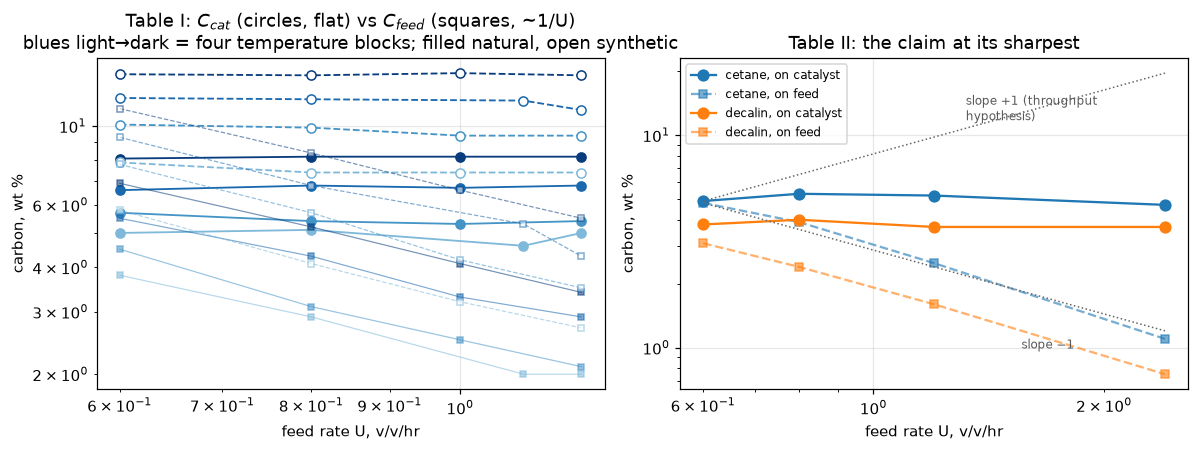

In [16]:
# figure: both carbon columns against feed rate, log-log
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=False)
blues = plt.cm.Blues(np.linspace(0.45, 0.95, 4))
for cat in ("natural", "synthetic"):
    ls = "-" if cat == "natural" else "--"
    for b in range(1, 5):
        g = t1[(t1.catalyst == cat) & (t1.block == b)]
        ax[0].loglog(g.feed_rate_vvhr, g.C_cat_wtpct, "o" + ls, color=blues[b - 1],
                     mfc=("white" if cat == "synthetic" else None), ms=6, lw=1.2)
        ax[0].loglog(g.feed_rate_vvhr, g.C_feed_wtpct, "s" + ls, color=blues[b - 1],
                     mfc=("white" if cat == "synthetic" else None), ms=4, lw=0.8, alpha=0.55)
ax[0].set_xlabel("feed rate U, v/v/hr"); ax[0].set_ylabel("carbon, wt %")
ax[0].set_title("Table I: $C_{cat}$ (circles, flat) vs $C_{feed}$ (squares, ~1/U)\n"
                "blues light→dark = four temperature blocks; filled natural, open synthetic")
for feed, c in [("cetane", "tab:blue"), ("decalin", "tab:orange")]:
    g = t2[t2.feed == feed]
    ax[1].loglog(g.feed_rate_vvhr, g.C_cat_wtpct, "o-", color=c, ms=7, label=f"{feed}, on catalyst")
    ax[1].loglog(g.feed_rate_vvhr, g.C_feed_wtpct, "s--", color=c, ms=5, alpha=0.6,
                 label=f"{feed}, on feed")
g = t2[t2.feed == "cetane"]
uu = np.array([g.feed_rate_vvhr.min(), g.feed_rate_vvhr.max()])
ax[1].loglog(uu, g.C_cat_wtpct.iloc[0] * (uu / uu[0]), ":", color="0.4", lw=1)
ax[1].text(uu[0] * 2.2, g.C_cat_wtpct.iloc[0] * 2.4, "slope +1 (throughput\nhypothesis)", fontsize=8, color="0.35")
ax[1].loglog(uu, g.C_feed_wtpct.iloc[0] * (uu[0] / uu), ":", color="0.4", lw=1)
ax[1].text(uu[0] * 2.6, g.C_feed_wtpct.min() * 0.9, "slope −1", fontsize=8, color="0.35")
ax[1].set_xlabel("feed rate U, v/v/hr"); ax[1].set_ylabel("carbon, wt %")
ax[1].set_title("Table II: the claim at its sharpest")
ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

### 2. The two carbon columns are one measurement, so each table carries *one* test

The paper states how Table I was measured: *"After each run the catalyst was
discharged from the unit and analyzed for carbon by combustion"*: one carbon
determination per run. The two printed columns are then related by the paper's
own eq.-(4) bookkeeping: $C_c = C_f \cdot W\theta/60$ with $W = U\,D_o/D_c$,
so the ratio

$$\frac{W}{U}\Big|_{implied} = \frac{C_c}{C_f\cdot U\cdot(\theta/60)}
   \;\left(= \frac{D_o}{D_c}\right)$$

should be a **constant of the unit and charge, row by row**: and if it is
constant, the two columns carry the same information and $m_{cat}\approx0$
*is* $m_{feed}\approx-1$ restated. Checking its constancy simultaneously (a)
tests that reading, (b) cross-checks all four transcribed columns at once (a
mis-read digit breaks its own row), and (c) recovers the number the paper
never prints for these units: the density ratio the eq.-(5) derivation would
have needed *here* (the only density ratio printed anywhere in the five pages
is the one on p. 321, inside the fluid-oriented eq.-(5) derivation; the
Nomenclature defines $D_o$, $D_c$ without values).

The two columns also obey an exact identity that is worth knowing before
reading the slopes: $\ln C_{cat} = \ln C_{feed} + \ln U + \mathrm{const} +
\ln(W/U)$ row by row, and least-squares slopes add, so inside every group
$m_{cat} = m_{feed} + 1 + s_{W/U}$, where $s_{W/U}$ is the slope of $\ln(W/U)$
on $\ln U$. The two exponents of section 1 are therefore the same number up to
how much the implied ratio drifts with the feed rate.

In [17]:
WU = X["WU"]
print(f"{'group':22s} {'mean':>7s} {'CV %':>6s}  rows")
for key, r in WU.items():
    print(f"{key:22s} {r.mean():7.3f} {100 * r.std(ddof=0) / r.mean():6.1f}  " + " ".join(f"{v:.3f}" for v in r))

say(r"""Within-group scatter: worst CV <<WU_within_group_cv_max_pct:.1f>> %, against a per-row
half-digit allowance of up to <<WU_half_digit_allowance_max_pct:.1f>> % (<<row>>, whose small
one-decimal carbon cells dominate; each cell's allowance comes from its own printed decimals, so
a two-decimal cell gets a hundredth of that). The constancy is at the rounding floor: consistent
with, and at this precision indistinguishable from, both columns being computed from **one**
carbon determination through the run's fixed feed-to-catalyst mass ratio. Two independent
balances agreeing this well on all <<n_rows:d>> rows is not excluded, but either way the columns
are redundant **at the printed precision**, so the feed-rate claim gets one test per group, not two.

The slope identity above is exact on this page: the largest gap between $m_{cat} - m_{feed} - 1$
and $s_{W/U}$ over the <<n_groups:d>> groups is within <<max_slope_decomposition_gap:.0e>> (here <<slope_decomposition_gap:.0e>>), and
the largest $|s_{W/U}|$ is <<WU_slope_vs_feed_worst_abs:.3f>>, which is how far the two exponents
of section 1 can differ from $m_{feed} + 1 = m_{cat}$ on these rows.

Implied $W/U$ (= $D_o/D_c$ of eq. 4): natural <<WU_implied_natural:.3f>>, synthetic
<<WU_implied_synthetic:.3f>>, cetane <<WU_implied_cetane:.3f>>, decalin <<WU_implied_decalin:.3f>>.
Decalin over cetane is <<WU_decalin_over_cetane:.3f>>: same unit, same catalyst, so $W = U D_o/D_c$
attributes the whole difference to the two liquids' density ratio; the paper prints no densities, so
this is a consistency observation, not a check against known values. None of the four is the
$1/<<eq4_density_ratio:g>> = <<inv:.3f>>$ printed for the eq.-(5) unit; that ratio belongs to that
study and would be wrong here.""", row=X["allowance_row"], n_rows=len(t1) + len(t2), n_groups=len(sl),
    inv=1 / K["eq4_density_ratio"], V=V)

group                     mean   CV %  rows
natural1                 1.071    2.5  1.096 1.099 1.045 1.042
natural2                 1.069    1.2  1.056 1.089 1.060 1.071
natural3                 0.995    1.4  1.000 0.988 1.015 0.977
natural4                 0.992    1.1  0.978 0.986 1.000 1.005
synthetic1               1.140    0.9  1.135 1.128 1.156 1.142
synthetic2               1.101    1.7  1.079 1.086 1.119 1.119
synthetic3               1.064    2.9  1.075 1.094 1.012 1.076
synthetic4               1.049    1.2  1.042 1.034 1.068 1.053
cetane                   0.864    1.9  0.851 0.849 0.867 0.890
decalin                  1.014    2.9  1.022 1.042 0.964 1.028


Within-group scatter: worst CV 2.9 %, against a per-row
half-digit allowance of up to 5.9 % (cetane, U = 2.4, whose small
one-decimal carbon cells dominate; each cell's allowance comes from its own printed decimals, so
a two-decimal cell gets a hundredth of that). The constancy is at the rounding floor: consistent
with, and at this precision indistinguishable from, both columns being computed from **one**
carbon determination through the run's fixed feed-to-catalyst mass ratio. Two independent
balances agreeing this well on all 40 rows is not excluded, but either way the columns
are redundant **at the printed precision**, so the feed-rate claim gets one test per group, not two.

The slope identity above is exact on this page: the largest gap between $m_{cat} - m_{feed} - 1$
and $s_{W/U}$ over the 10 groups is within 1e-12 (here 9e-16), and
the largest $|s_{W/U}|$ is 0.085, which is how far the two exponents
of section 1 can differ from $m_{feed} + 1 = m_{cat}$ on these rows.

Implied $W/U$ (= $D_o/D_c$ of eq. 4): natural 1.032, synthetic
1.089, cetane 0.864, decalin 1.014.
Decalin over cetane is 1.173: same unit, same catalyst, so $W = U D_o/D_c$
attributes the whole difference to the two liquids' density ratio; the paper prints no densities, so
this is a consistency observation, not a check against known values. None of the four is the
$1/0.58 = 1.724$ printed for the eq.-(5) unit; that ratio belongs to that
study and would be wrong here.

In [18]:
say(r"""**One systematic residual, reported and not explained.** The implied ratio drifts *down*
across the temperature blocks: natural <<bm_nat1:.3f>> to <<bm_nat4:.3f>>, synthetic
<<bm_syn1:.3f>> to <<bm_syn4:.3f>> from the lowest to the highest block, a block-1 over block-4
ratio minus one of <<WU_block_drift_natural_pct:+.1f>> % and <<WU_block_drift_synthetic_pct:+.1f>> %.
Against the scatter of the four rows in each block (the standard error of the block mean, combined
for the two blocks) the drift is <<WU_block_drift_natural_over_se:.1f>> and
<<WU_block_drift_synthetic_over_se:.1f>> standard errors (each block mean rests on four rows, so about
six degrees of freedom), so it is larger than the within-block scatter. A charging mass ratio has no business varying with temperature, and nothing in the paper
explains it. It does not touch the feed-rate verdict, which lives within blocks.

**The row whose feed-rate glyph the sidecar discusses.** The synthetic 911 °F row prints
$U = 1.1$. Read so, its implied ratio sits <<abs_asread:.1f>> % below the other three rows of its
block; read as $<<alt:g>>$ it would sit <<WU_glyph_row_dev_if_1p0_pct:+.1f>> % from them. The identity
cannot adjudicate a glyph this small: the pixels can, and did (the glyph is unambiguous, 1.1 is kept).""",
    bm_nat1=X["bm_natural"][0], bm_nat4=X["bm_natural"][1], bm_syn1=X["bm_synthetic"][0],
    bm_syn4=X["bm_synthetic"][1], abs_asread=abs(R["WU_glyph_row_dev_as_read_pct"]),
    alt=GLYPH_ALTERNATIVE, V=V)

**One systematic residual, reported and not explained.** The implied ratio drifts *down*
across the temperature blocks: natural 1.071 to 0.992, synthetic
1.140 to 1.049 from the lowest to the highest block, a block-1 over block-4
ratio minus one of +7.9 % and +8.7 %.
Against the scatter of the four rows in each block (the standard error of the block mean, combined
for the two blocks) the drift is 4.6 and
9.1 standard errors (each block mean rests on four rows, so about
six degrees of freedom), so it is larger than the within-block scatter. A charging mass ratio has no business varying with temperature, and nothing in the paper
explains it. It does not touch the feed-rate verdict, which lives within blocks.

**The row whose feed-rate glyph the sidecar discusses.** The synthetic 911 °F row prints
$U = 1.1$. Read so, its implied ratio sits 6.4 % below the other three rows of its
block; read as $1$ it would sit +2.9 % from them. The identity
cannot adjudicate a glyph this small: the pixels can, and did (the glyph is unambiguous, 1.1 is kept).

### 3. The printed algebra chain, (2)+(3)+(4) → (5), by two routes

The paper substitutes eq. (2) and eq. (3) into the mass balance (4) and prints the
result as eq. (5). The chain is closed-form, so it can be checked to machine
precision, by two routes with **independent solvers**:

- **route A, symbolic**: exact rationals in `sympy`, the isolation of $V$ and its
  logarithmic derivatives;
- **route B, numeric**: the chain is *root-found* for $V$ on the physical range
  0 to 100 % with `pymrm.checks.find_roots` (which raises unless it finds exactly
  one root), point by point on a $(U,\theta)$ grid, and the power-law form is
  recovered by least squares of $\ln V$ on $(1, \ln U, \ln\theta)$ with no
  computer algebra involved.

**What the two routes share:** the one hand isolation of $V^{2.93}$ from
(2)+(3)+(4) and the five input constants. Their agreement therefore checks the
solvers, not that step. The check on the shared step is external: an error in it
would move the derived coefficient away from the *printed* 96, and the comparison
against the printed triple below catches that.

In [19]:
c_sym, eu_sym, et_sym = X["chain"]
say(r"""eq. (5) re-derived from eqs. (2)+(3)+(4):

- route A (symbolic): $V = <<eq5_coeff_symbolic:.4f>> / (U^{<<eq5_expU_symbolic:.5f>>}\,\theta^{<<eq5_expTheta_symbolic:.5f>>})$
- route B (root find and least squares): $V = <<eq5_coeff_numeric:.4f>> / (U^{<<eq5_expU_numeric:.5f>>}\,\theta^{<<eq5_expTheta_numeric:.5f>>})$
- printed: $V = <<eq5_coeff:g>> / (U^{<<eq5_expU:g>>}\,\theta^{<<eq5_expTheta:g>>})$

The routes agree to within <<max_eq5_route_gap_max:.0e>> (here <<eq5_route_gap_max:.0e>>; relative for the
coefficient, absolute for the exponents; set by the root tolerance), and the power-law fit of route B
leaves a log-residual within <<max_eq5_numeric_fit_residual:.0e>> (here <<eq5_numeric_fit_residual:.0e>>)
on the grid: the chain *is* exactly a power law,
which route B verifies rather than assumes. Every printed digit is the rounding of the exact chain:
<<eq5_coeff_symbolic:.4f>> to <<eq5_coeff:g>>, <<eq5_expU_symbolic:.5f>> to <<eq5_expU:g>>,
<<eq5_expTheta_symbolic:.5f>> to <<eq5_expTheta:g>> (claim `eq5_hits_printed`). The exponents are the
identities $1/<<eq3_exp:g>> = <<inv_e3:.5f>>$ for $U$ and $(1 - <<eq2_n:g>>)/<<eq3_exp:g>> =
<<et_id:.5f>>$ for $\theta$.

What the printed rounding costs: the ratio of the printed form to the exact chain is a power
law in $U$ and $\theta$, so its extreme over a window is at a corner. Over
$U = <<u0:g>>$ to $<<u1:g>>$ v/v/hr and $\theta = <<t0:g>>$ to $<<t1:g>>$ min (a window chosen
here, not the paper's) the worst deviation is <<eq5_printed_rounding_worst_pct:.2f>> %: the
printed rounding is harmless there.

A small exact object the paper does not print: $V(\theta)$ is the *period-average* conversion,
so the instantaneous conversion the chain implies is $d(\theta V)/d\theta = (1 - <<eq5_expTheta_symbolic:.4f>>)\,V
= <<inst_over_avg_conversion:.4f>>\,V$. At every moment the instantaneous conversion sits at
<<inst_pct:.1f>> % of the period average to date, declining and never negative, so the derived
correlation is self-consistent as an averaged quantity.""",
    inv_e3=1 / K["eq3_exp"], et_id=(1 - K["eq2_n"]) / K["eq3_exp"], u0=U_WIN[0], u1=U_WIN[1],
    t0=TH_WIN[0], t1=TH_WIN[1], inst_pct=100 * R["inst_over_avg_conversion"], V=V)

eq. (5) re-derived from eqs. (2)+(3)+(4):

- route A (symbolic): $V = 95.7145 / (U^{0.34130}\,\theta^{0.19113})$
- route B (root find and least squares): $V = 95.7145 / (U^{0.34130}\,\theta^{0.19113})$
- printed: $V = 96 / (U^{0.34}\,\theta^{0.19})$

The routes agree to within 1e-09 (here 1e-15; relative for the
coefficient, absolute for the exponents; set by the root tolerance), and the power-law fit of route B
leaves a log-residual within 1e-09 (here 4e-15)
on the grid: the chain *is* exactly a power law,
which route B verifies rather than assumes. Every printed digit is the rounding of the exact chain:
95.7145 to 96, 0.34130 to 0.34,
0.19113 to 0.19 (claim `eq5_hits_printed`). The exponents are the
identities $1/2.93 = 0.34130$ for $U$ and $(1 - 0.44)/2.93 =
0.19113$ for $\theta$.

What the printed rounding costs: the ratio of the printed form to the exact chain is a power
law in $U$ and $\theta$, so its extreme over a window is at a corner. Over
$U = 0.3$ to $1.2$ v/v/hr and $\theta = 30$ to $240$ min (a window chosen
here, not the paper's) the worst deviation is 0.94 %: the
printed rounding is harmless there.

A small exact object the paper does not print: $V(\theta)$ is the *period-average* conversion,
so the instantaneous conversion the chain implies is $d(\theta V)/d\theta = (1 - 0.1911)\,V
= 0.8089\,V$. At every moment the instantaneous conversion sits at
80.9 % of the period average to date, declining and never negative, so the derived
correlation is self-consistent as an averaged quantity.

In [20]:
# What the chain can and cannot pin: which misreadings of its five inputs still round to
# the printed triple.
print("misreadings of a leading digit, a transposed glyph or an exponent scale:")
print(f"{'misreading':34s} {'coeff':>9s} {'expU':>7s} {'expT':>7s} {'matches the printed triple?':>28s}")
for kw, c_, eu_, et_, h in X["misreadings"]:
    desc = ", ".join(f"{k} = {v:g}" for k, v in kw.items())
    print(f"{desc:34s} {c_:9.2f} {eu_:7.4f} {et_:7.4f} {'yes' if h else 'no':>28s}")
print("\nEvery last-digit +-1 alternative of the five inputs:")
print(f"{'alternative reading':34s} {'coeff':>9s} {'expU':>7s} {'expT':>7s} {'matches?':>9s}")
for name, val, c_, eu_, et_, h in X["alternatives"]:
    print(f"{name + ' read as ' + format(val, 'g'):34s} {c_:9.2f} {eu_:7.4f} {et_:7.4f} {'yes' if h else 'no':>9s}")
surv = sorted({a[0] for a in X["alternatives"] if a[5]})
pinned = sorted({a[0] for a in X["alternatives"]} - set(surv))
say(r"""**What the chain certifies, and what it cannot.** <<n_mis:d>> of the <<n_mis_tot:d>> misreadings
above round to the printed triple, so the re-derivation excludes every leading-digit,
transposed-glyph and exponent-scale misreading tried. It does **not** pin every last digit:
<<eq5_last_digit_alternatives_matching:d>> of the <<eq5_last_digit_alternatives_total:d>> last-digit
alternatives still round to the printed (<<eq5_coeff:g>>, <<eq5_expU:g>>, <<eq5_expTheta:g>>), at least one
for each of <<surv>>; those final digits rest on the digit-scale crops alone, read independently twice,
at transcription and again at verification, in agreement. The exponent of eq. (3) is pinned:
<<eq5_e3_alternatives_matching:d>> of its two alternatives round to the printed triple.""",
    n_mis=R["eq5_misreadings_matching"], n_mis_tot=len(X["misreadings"]),
    surv=", ".join(f"`{s}`" for s in surv), V=V)

misreadings of a leading digit, a transposed glyph or an exponent scale:
misreading                             coeff    expU    expT  matches the printed triple?
e3v = 2.98                             88.66  0.3356  0.1879                           no
e3v = 2.63                            161.04  0.3802  0.2129                           no
drv = 0.53                             92.81  0.3413  0.1911                           no
c3v = 3.55e-06                        210.03  0.3413  0.1911                           no
n2v = 0.41                             95.71  0.3413  0.2014                           no
A2v = 0.85                            104.89  0.3413  0.1911                           no

Every last-digit +-1 alternative of the five inputs:
alternative reading                    coeff    expU    expT  matches?
eq2_A read as 0.66                     96.21  0.3413  0.1911       yes
eq2_A read as 0.64                     95.21  0.3413  0.1911        no
eq2_n read as 0.45            

**What the chain certifies, and what it cannot.** 0 of the 6 misreadings
above round to the printed triple, so the re-derivation excludes every leading-digit,
transposed-glyph and exponent-scale misreading tried. It does **not** pin every last digit:
6 of the 10 last-digit
alternatives still round to the printed (96, 0.34, 0.19), at least one
for each of `eq2_A`, `eq2_n`, `eq3_coeff`, `eq4_density_ratio`; those final digits rest on the digit-scale crops alone, read independently twice,
at transcription and again at verification, in agreement. The exponent of eq. (3) is pinned:
0 of its two alternatives round to the printed triple.

In [21]:
V36, V41 = K["faulty_measured_pct"], K["faulty_predicted_pct"]
say(r"""**The "faulty point" remark, made quantitative (labelled inference).** p. 321 twice flags
'the point at about <<faulty_measured_pct:g>>% conversion' as a possibly faulty determination, 'in
which case the predicted value would be <<faulty_predicted_pct:g>>%'. The point itself lives only in
Fig. 3 (not digitised), but eq. (3) makes the remark quantitative without it: a predicted
<<faulty_predicted_pct:g>> % implies that the run's measured carbon on feed was
$C_f = <<c3m:.2f>>\times10^{-5}\cdot <<faulty_predicted_pct:g>>^{<<eq3_exp:g>>} = <<faulty_point_implied_Cf_wtpct:.3f>>$ wt %,
where the correlation at the measured <<faulty_measured_pct:g>> % gives <<faulty_point_online_Cf_wtpct:.3f>> wt %.
The flagged point therefore sits a factor <<faulty_point_excess_ratio:.2f>> above the line in carbon yield.
This is exact given eq. (3) and the two printed percentages, and it is not checkable further without
the figure.""", c3m=K["eq3_coeff"] * 1e5, V=V)

**The "faulty point" remark, made quantitative (labelled inference).** p. 321 twice flags
'the point at about 36% conversion' as a possibly faulty determination, 'in
which case the predicted value would be 41%'. The point itself lives only in
Fig. 3 (not digitised), but eq. (3) makes the remark quantitative without it: a predicted
41 % implies that the run's measured carbon on feed was
$C_f = 3.55\times10^{-5}\cdot 41^{2.93} = 1.887$ wt %,
where the correlation at the measured 36 % gives 1.289 wt %.
The flagged point therefore sits a factor 1.46 above the line in carbon yield.
This is exact given eq. (3) and the two printed percentages, and it is not checkable further without
the figure.

### 4. The printed doubling interval: the paper's fit, measured per catalyst

Fig. 2 is drawn *from Table I* (p. 320: "The data in Table I permit a study of
the effect of temperature"), so testing the printed doubling interval against
Table I is a **goodness-of-fit check of the author's own correlation on the
author's own data**, labelled as such here, in `meta.yaml` and in the README.
The doubling interval is $\Delta T_2 = \ln 2 / (d\ln C_c/dT)$, with $\ln C_{cat}$
fitted to $T$ per catalyst over all its rows (the feed-rate scatter enters as
noise; that is what the claim itself does by drawing one line per catalyst through
all feed rates), with the standard error of the fitted slope carried to the
interval. A second, regression-free estimate uses the means of the two extreme
temperature blocks; it uses the same rows, so it is a second weighting of the same
data, not independent evidence.

In [22]:
nat, syn = t1[t1.catalyst == "natural"], t1[t1.catalyst == "synthetic"]
say(r"""| catalyst | doubling interval, fit to all rows | standard error | two-point (block means) | distance from the printed band |
|---|---|---|---|---|
| natural | <<doubling_dT_natural_F:.1f>> °F | <<doubling_dT_natural_se_F:.1f>> °F | <<doubling_dT_natural_twopoint_F:.1f>> °F | <<doubling_natural_vs_band_high_se:+.1f>> standard errors from the band's upper end, <<doubling_high_F:g>> °F |
| synthetic | <<doubling_dT_synthetic_F:.1f>> °F | <<doubling_dT_synthetic_se_F:.1f>> °F | <<doubling_dT_synthetic_twopoint_F:.1f>> °F | <<doubling_synthetic_vs_band_low_se:+.1f>> standard errors from the band's lower end, <<doubling_low_F:g>> °F |

The printed claim is that carbon formation "doubles for approximately <<doubling_low_F:g>> to
<<doubling_high_F:g>> °F". The band sits **between** the two catalysts: the natural catalyst
(<<doubling_dT_natural_F:.0f>> °F) is within <<nat_abs:.1f>> standard errors of the band's upper end,
so its own rows do not contradict the band; the synthetic catalyst (<<doubling_dT_synthetic_F:.0f>> °F)
is <<syn_abs:.1f>> standard errors below the band's lower end on a straight line through its rows, which
the rows reject (quadratic term <<doubling_quadratic_t_synthetic:+.1f>> standard errors; natural
<<doubling_quadratic_t_natural:+.1f>>): the 16 rows sit at four temperatures and curve, so the row
standard errors treat four temperature levels as 16 independent points. On the four block means of
each catalyst (2 degrees of freedom) the intervals are <<doubling_dT_natural_blockmean_F:.1f>> $\pm$
<<doubling_dT_natural_blockmean_se_F:.1f>> °F (<<doubling_natural_vs_band_blockmean_se:+.1f>> standard
errors from the band's upper end) and <<doubling_dT_synthetic_blockmean_F:.1f>> $\pm$
<<doubling_dT_synthetic_blockmean_se_F:.1f>> °F (<<doubling_synthetic_vs_band_low_blockmean_se:+.1f>> standard
errors from the band's lower end): on its four block means the synthetic catalyst is
<<syn_bm_abs:.1f>> standard errors below the band, not <<syn_abs:.1f>>. The two catalysts differ by
<<doubling_dT_split_F:.1f>> °F, <<doubling_dT_split_over_se:.1f>> standard errors of that difference on the
row fits and <<doubling_dT_split_over_se_blockmean:.1f>> on the block means. As a pooled one-number summary
of Fig. 2 the band is a fair reading. Goodness of fit, not validation: claim and data are the same paper's.""",
    nat_abs=abs(R["doubling_natural_vs_band_high_se"]), syn_abs=abs(R["doubling_synthetic_vs_band_low_se"]),
    syn_bm_abs=abs(R["doubling_synthetic_vs_band_low_blockmean_se"]), V=V)

| catalyst | doubling interval, fit to all rows | standard error | two-point (block means) | distance from the printed band |
|---|---|---|---|---|
| natural | 205.6 °F | 7.1 °F | 208.3 °F | +0.8 standard errors from the band's upper end, 200 °F |
| synthetic | 175.8 °F | 4.8 °F | 174.0 °F | -3.0 standard errors from the band's lower end, 190 °F |

The printed claim is that carbon formation "doubles for approximately 190 to
200 °F". The band sits **between** the two catalysts: the natural catalyst
(206 °F) is within 0.8 standard errors of the band's upper end,
so its own rows do not contradict the band; the synthetic catalyst (176 °F)
is 3.0 standard errors below the band's lower end on a straight line through its rows, which
the rows reject (quadratic term -3.6 standard errors; natural
+2.5): the 16 rows sit at four temperatures and curve, so the row
standard errors treat four temperature levels as 16 independent points. On the four block means of
each catalyst (2 degrees of freedom) the intervals are 205.4 $\pm$
13.7 °F (+0.4 standard
errors from the band's upper end) and 176.0 $\pm$
9.4 °F (-1.5 standard
errors from the band's lower end): on its four block means the synthetic catalyst is
1.5 standard errors below the band, not 3.0. The two catalysts differ by
29.8 °F, 3.5 standard errors of that difference on the
row fits and 1.8 on the block means. As a pooled one-number summary
of Fig. 2 the band is a fair reading. Goodness of fit, not validation: claim and data are the same paper's.

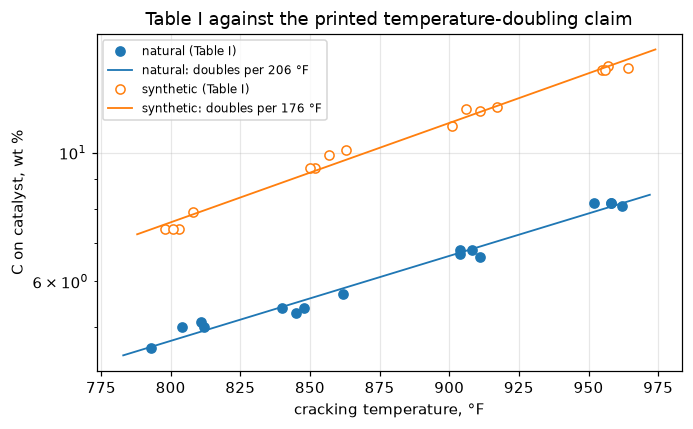

In [23]:
fig, ax = plt.subplots(figsize=(6.4, 4.0))
for cat, c, mfc in [("natural", "tab:blue", None), ("synthetic", "tab:orange", "white")]:
    g = t1[t1.catalyst == cat]
    ax.semilogy(g.temp_F, g.C_cat_wtpct, "o", color=c, mfc=mfc, label=f"{cat} (Table I)")
    tt = np.linspace(g.temp_F.min() - 10, g.temp_F.max() + 10, 50)
    s = np.log(2.0) / R[f"doubling_dT_{cat}_F"]
    b0 = np.mean(np.log(g.C_cat_wtpct)) - s * g.temp_F.mean()       # the OLS line passes through the means
    ax.semilogy(tt, np.exp(b0 + s * tt), "-", color=c, lw=1.2,
                label=f"{cat}: doubles per {R[f'doubling_dT_{cat}_F']:.0f} °F")
ax.set_xlabel("cracking temperature, °F"); ax.set_ylabel("C on catalyst, wt %")
ax.set_title("Table I against the printed temperature-doubling claim")
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

In [24]:
sd = X["doubling_slopes"]
say(r"""**What the carbon-on-feed column would give.** The same fit on the carbon on feed gives a
doubling interval of <<doubling_dT_natural_feed_F:.0f>> °F for the natural catalyst, not
<<doubling_dT_natural_F:.0f>> °F, so a column mix-up would not go unnoticed, and the printed claim
is specifically a claim about carbon on catalyst. Why they differ is an exact decomposition, not a
guess: $\ln C_{feed} = \ln C_{cat} - \ln U - \ln(W/U) - \mathrm{const}$ row by row, and least-squares
slopes against $T$ add, so $s_{feed} = s_{cat} - s_U - s_{W/U}$ with
$s_{cat} = <<s_cat:.5f>>$, $s_U = <<s_U:+.5f>>$ (feed rate happens to correlate with temperature
across the pooled rows), $s_{W/U} = <<s_WU:+.5f>>$ (the drift of the implied ratio of section 2) and
$s_{feed} = <<s_feed:.5f>>$ per °F; the identity closes to within <<max_doubling_decomposition_gap:.0e>> (here <<doubling_decomposition_gap:.0e>>). Carrying
only the feed-rate term moves the interval from <<doubling_dT_natural_F:.0f>> to
<<doubling_dT_natural_linked_F:.0f>> °F (fit of $\ln(C_{cat}/U)$ on $T$), and the drift of the implied
ratio moves it the rest of the way to <<doubling_dT_natural_feed_F:.0f>> °F.""",
    s_cat=sd["cat"], s_U=sd["U"], s_WU=sd["WU"], s_feed=sd["feed"], V=V)

**What the carbon-on-feed column would give.** The same fit on the carbon on feed gives a
doubling interval of 155 °F for the natural catalyst, not
206 °F, so a column mix-up would not go unnoticed, and the printed claim
is specifically a claim about carbon on catalyst. Why they differ is an exact decomposition, not a
guess: $\ln C_{feed} = \ln C_{cat} - \ln U - \ln(W/U) - \mathrm{const}$ row by row, and least-squares
slopes against $T$ add, so $s_{feed} = s_{cat} - s_U - s_{W/U}$ with
$s_{cat} = 0.00337$, $s_U = -0.00052$ (feed rate happens to correlate with temperature
across the pooled rows), $s_{W/U} = -0.00058$ (the drift of the implied ratio of section 2) and
$s_{feed} = 0.00447$ per °F; the identity closes to within 1e-12 (here 0e+00). Carrying
only the feed-rate term moves the interval from 206 to
178 °F (fit of $\ln(C_{cat}/U)$ on $T$), and the drift of the implied
ratio moves it the rest of the way to 155 °F.

### 5. The diffusion hypothesis: the printed exponents, and the factor-of-two defect in the nomenclature

**The factor-of-two defect, from the paper's own two lines.** Eq. (8) prints
$dC_c/d\theta = K/C_c$ "or" $C_c = A\theta^{0.5}$, and the Nomenclature prints
verbatim: **"$K$ = constant $(= A^2)$"**. The two printed lines of eq. (8) fix
the relation between $K$ and $A$ with no freedom: separate and integrate from
a clean catalyst ($C_c(0)=0$) and $C_c = \sqrt{2K\theta}$, so $K = A^2/2$,
or differentiate the right-hand line: $dC_c/d\theta = 0.5\,A^2/C_c$, same
answer. The printed parenthesis is off by exactly 2 (equivalently $\sqrt2$ in
$A$). $K$ appears nowhere else in the paper, so nothing downstream inherits
the defect. Reported, not repaired; both derivations below, the second by an
ODE integrator that shares nothing with the symbolic route.

In [25]:
say(r"""route A (symbolic): $dC/d\theta = K/C$ with $C(0) = 0$ gives $C = <<csym>>$; matching
$C = A\theta^{0.5}$ requires $K/A^2 = <<K_over_A2_required:g>>$ (printed: 1). This result is exact and
independent of every printed number (claim `K_over_A2_required`, structural).

route B (`solve_ivp`, $A = <<eq2_A:g>>$): integrating with the **printed** $K = A^{<<K_identification:g>>}$
the deposit overshoots $A\theta^{0.5}$ by <<K_printed_numeric_overshoot:.6f>> ($\sqrt2 = <<sqrt2:.6f>>$);
with $K = A^2/2$ the ratio differs from 1 by less than <<max_K_half_numeric_gap:.0e>> (here <<K_half_numeric_gap:.0e>>).
Tightening the tolerance of the integration by a factor of 100 moves either ratio by less than
<<max_K_numeric_tolerance_shift:.0e>> (here <<K_numeric_tolerance_shift:.0e>>).""",
    csym=sp.latex(C_SYMBOLIC), sqrt2=np.sqrt(2), V=V)

route A (symbolic): $dC/d\theta = K/C$ with $C(0) = 0$ gives $C = \sqrt{2} \sqrt{K} \sqrt{\theta}$; matching
$C = A\theta^{0.5}$ requires $K/A^2 = 0.5$ (printed: 1). This result is exact and
independent of every printed number (claim `K_over_A2_required`, structural).

route B (`solve_ivp`, $A = 0.65$): integrating with the **printed** $K = A^{2}$
the deposit overshoots $A\theta^{0.5}$ by 1.414214 ($\sqrt2 = 1.414214$);
with $K = A^2/2$ the ratio differs from 1 by less than 1e-08 (here 1e-11).
Tightening the tolerance of the integration by a factor of 100 moves either ratio by less than
1e-08 (here 2e-11).

**How close is "close enough to 0.5"?** The paper: the four exponents "are all
close enough to 0.5 to suggest a good concordance with the theory advanced
above." The hypothesis is exercised on every printed $(A, n)$ pair by asking
what each correlation says about the quantity the hypothesis holds constant,
$C_c\,dC_c/d\theta = n A^2 \theta^{2n-1}$, which is constant iff $n = 0.5$, across
a window of residence times chosen here (not the paper's).

In [26]:
print(f"C dC/dtheta = n A^2 theta^(2n-1): variation over theta = {TH_LO:g}-{TH_HI:g} min")
print(f"{'eq.':>4s} {'A':>6s} {'n':>6s}   {'(theta_hi/lo)^(2n-1)':>22s}   {'drift from constant':>20s}")
for eq, (ak, nk) in {"(1)": ("eq1_A", "eq1_n"), "(2)": ("eq2_A", "eq2_n"),
                     "(6)": ("eq6_A", "eq6_n"), "(7)": ("eq7_A", "eq7_n")}.items():
    ratio = (TH_HI / TH_LO) ** (2 * K[nk] - 1)
    print(f"{eq:>4s} {K[ak]:6.2f} {K[nk]:6.2f}   {ratio:22.3f}   {X['drift'][eq]:19.1f} %")
say(r"""Under the hypothesis's own invariant the printed exponents are not uniformly 'close to 0.5': the
worst is eq. <<worst>> with a drift of <<hypothesis_drift_worst_pct:.0f>> % over the window, the
smallest eq. <<best>> with <<hypothesis_drift_best_pct:.0f>> %. The paper's qualitative suggestion
survives; a quantitative $n = 0.5$ does not, and the paper itself never claims it does ('n = constant,
depending only slightly on ...').""", worst=X["drift_worst_eq"], best=X["drift_best_eq"], V=V)

C dC/dtheta = n A^2 theta^(2n-1): variation over theta = 10-300 min
 eq.      A      n     (theta_hi/lo)^(2n-1)    drift from constant
 (1)   0.86   0.41                    0.542                  45.8 %
 (2)   0.65   0.44                    0.665                  33.5 %
 (6)   0.52   0.38                    0.442                  55.8 %
 (7)   0.24   0.53                    1.226                  22.6 %


Under the hypothesis's own invariant the printed exponents are not uniformly 'close to 0.5': the
worst is eq. (6) with a drift of 56 % over the window, the
smallest eq. (7) with 23 %. The paper's qualitative suggestion
survives; a quantitative $n = 0.5$ does not, and the paper itself never claims it does ('n = constant,
depending only slightly on ...').

In [27]:
say(r"""**$A$ is local, $n$ is portable: the paper's own two campaigns.** Eq. (2), from the Fig.-1 study
(one repeatedly regenerated batch), predicts $C_c(<<theta_tables_min:g>>\ \mathrm{min}) =
<<eq2_prediction_at_120min_wtpct:.2f>>$ wt %. Table I's synthetic block 2 (about <<tblk:.0f>> °F; a fresh
batch every run) prints <<cblk_lo:.1f>> to <<cblk_hi:.1f>> wt %, a factor <<A_campaign_gap_ratio:.2f>> on
the block mean. East Texas gas oil, synthetic catalyst, 850 °F and the same residence time in both; only the
unit and the catalyst batch differ. That is the Nomenclature's asymmetry made concrete: $A$ moved by
<<gap_pct:.0f>> % between campaigns of the same laboratory, while $n$ stays between
<<n_printed_min:g>> and <<n_printed_max:g>> across two modes, three oils and two catalyst types. The four
printed $A$ span a factor <<A_span_factor:.1f>>; the four exponents span
<<n_printed_min:g>> to <<n_printed_max:g>>, $\pm<<n_span_half_range_pct:.0f>>$ % about their midpoint.""",
    tblk=t1[(t1.catalyst == "synthetic") & (t1.block == 2)].temp_F.mean(),
    cblk_lo=t1[(t1.catalyst == "synthetic") & (t1.block == 2)].C_cat_wtpct.min(),
    cblk_hi=t1[(t1.catalyst == "synthetic") & (t1.block == 2)].C_cat_wtpct.max(),
    gap_pct=100 * (R["A_campaign_gap_ratio"] - 1), V=V)

**$A$ is local, $n$ is portable: the paper's own two campaigns.** Eq. (2), from the Fig.-1 study
(one repeatedly regenerated batch), predicts $C_c(120\ \mathrm{min}) =
5.34$ wt %. Table I's synthetic block 2 (about 856 °F; a fresh
batch every run) prints 9.4 to 10.1 wt %, a factor 1.82 on
the block mean. East Texas gas oil, synthetic catalyst, 850 °F and the same residence time in both; only the
unit and the catalyst batch differ. That is the Nomenclature's asymmetry made concrete: $A$ moved by
82 % between campaigns of the same laboratory, while $n$ stays between
0.38 and 0.53 across two modes, three oils and two catalyst types. The four
printed $A$ span a factor 3.6; the four exponents span
0.38 to 0.53, $\pm16$ % about their midpoint.

## Validation

No measurement outside the paper exists on this page, so validation means:
(a) internal identities the printed tables must satisfy (the implied catalyst-to-oil
ratio of section 2, the slope identity), (b) reproduction of printed algebra by two
routes (section 3), (c) every statement over a set computed over the whole set, with
standard errors where an estimate is compared with a value, and (d) a break table for
**every** number the page registers: each row injects a defect a reader of a 1945
bilevel scan could actually commit (a 3↔8 or 5↔6 glyph swap, a dropped superscript, a
swapped column, a unit misreading, a mistyped printed constant), reruns the arithmetic
of the whole page, and shows which numbers move.

**The registered numbers.** Every number the sections above print is registered below
with the way it is checked (`docs/claims-design.md`): a *value* is a data or
discretisation result, held in CI to a tight relative tolerance because the arithmetic
is deterministic and only a changed input moves it; a *bound* is a residual, an identity
or a tolerance effect; an *exact* result is a count, a flag or a printed constant, with
the distance to its rounding threshold where one decided it.

In [28]:
# Every number of the baseline run, registered with the way it is checked
# (docs/claims-design.md).
VALUE_RTOL = 1e-3   # deterministic arithmetic on printed data: only a changed input moves a value
for name, v in R.items():
    if name in BOUNDS:
        claims.bound(name, v, **BOUNDS[name])
    elif name in EXACT:
        claims.exact(name, v, **EXACT[name])
    else:
        claims.value(name, v, rtol=VALUE_RTOL)
print(f"{len(R)} numbers registered: {len(BOUNDS)} bounds, {len(EXACT)} exact, "
      f"{len(R) - len(BOUNDS) - len(EXACT)} values")

105 numbers registered: 6 bounds, 14 exact, 85 values


In [29]:
BREAK = []    # (injected defect, claim, clean value, broken value, caught)
REFUSED = []  # (injected defect, why) where the page's own one-root demand stopped the numeric route


def run_row(label, t1_=t1, t2_=t2, K_=K, **kw):
    """One injected defect: rerun the arithmetic of the whole page and record, for every
    claim, whether its own check catches the result."""
    R_, X_ = study(t1_, t2_, K_, refuse=True, **kw)
    if X_["refused"]:
        REFUSED.append((label, X_["refused"]))
    for name, v in R_.items():
        BREAK.append((label, name, claims[name], v, claims.breaks(label, name, v)))


def cell(df, sel, col, new):
    """A copy of ``df`` with ``col`` of the rows ``sel`` set to ``new``; returns the
    label of the change as well."""
    out = df.copy()
    old = out.loc[sel, col].iloc[0]
    out.loc[sel, col] = new
    return out, f"{col} {old:g} -> {new:g}"


def swapped(df, sel):
    out = df.copy()
    out.loc[sel, ["C_feed_wtpct", "C_cat_wtpct"]] = out.loc[sel, ["C_cat_wtpct", "C_feed_wtpct"]].to_numpy()
    return out


def misread(name, new):
    return f"{name} {K[name]:g} -> {new:g}", {**K, name: new}


is_nat = lambda d: d.catalyst == "natural"
is_syn = lambda d: d.catalyst == "synthetic"
cet_24 = (t2.feed == "cetane") & (t2.feed_rate_vvhr == 2.4)
dec_24 = (t2.feed == "decalin") & (t2.feed_rate_vvhr == 2.4)
syn906 = is_syn(t1) & (t1.temp_F == 906)
syn911 = is_syn(t1) & (t1.temp_F == 911)
nat962 = is_nat(t1) & (t1.temp_F == 962)
nat1_06 = is_nat(t1) & (t1.block == 1) & (t1.feed_rate_vvhr == 0.6)
syn4_06 = is_syn(t1) & (t1.block == 4) & (t1.feed_rate_vvhr == 0.6)
syn_b3 = is_syn(t1) & (t1.block == 3)

import inspect
DEF = {k: v.default for k, v in inspect.signature(study).parameters.items() if v.default is not inspect.Parameter.empty}
ROWS = []   # (label, keyword arguments of run_row)
for sel, col, new, where in [(cet_24, "C_cat_wtpct", 4.2, "Table II cetane, U 2.4"),
                             (cet_24, "feed_rate_vvhr", 1.4, "Table II cetane"),
                             (dec_24, "C_cat_wtpct", 3.2, "Table II decalin, U 2.4"),
                             (t2.feed_rate_vvhr == 0.6, "C_feed_wtpct", 4.3, "Table II, both feeds, U 0.6")]:
    d, lab = cell(t2, sel, col, new)
    ROWS.append((f"{where}: {lab}", dict(t2_=d)))
for sel, col, new, where in [(syn906, "C_feed_wtpct", 6.3, "Table I synthetic 906 F"),
                             (syn911, "C_cat_wtpct", 11.3, "Table I synthetic 911 F"),
                             (syn911, "feed_rate_vvhr", 1.0, "Table I synthetic 911 F"),
                             (nat962, "temp_F", 902, "Table I natural 962 F"),
                             (nat1_06, "C_cat_wtpct", 5.5, "Table I natural block 1, U 0.6"),
                             (syn4_06, "C_cat_wtpct", 13.0, "Table I synthetic block 4, U 0.6")]:
    d, lab = cell(t1, sel, col, new)
    ROWS.append((f"{where}: {lab}", dict(t1_=d)))
ROWS += [
    ("Table II: the two carbon columns swapped", dict(t2_=swapped(t2, t2.feed.notna()))),
    ("Table I synthetic block 3: the two carbon columns swapped", dict(t1_=swapped(t1, syn_b3))),
    ("Table I: the two carbon columns swapped", dict(t1_=swapped(t1, t1.feed_rate_vvhr > 0))),
    ("Table I: temperatures read as degrees C (x 5/9)", dict(t1_=t1.assign(temp_F=t1.temp_F * 5 / 9))),
    ("Table II: carbon on catalyst made proportional to the feed rate (throughput hypothesis)",
     dict(t2_=t2.assign(C_cat_wtpct=t2.C_cat_wtpct * t2.feed_rate_vvhr / t2.groupby("feed").feed_rate_vvhr.transform("min")))),
    ("Table I: carbon on catalyst made proportional to the feed rate (throughput hypothesis)",
     dict(t1_=t1.assign(C_cat_wtpct=t1.C_cat_wtpct * t1.feed_rate_vvhr
                        / t1.groupby(["catalyst", "block"]).feed_rate_vvhr.transform("min")))),
    (f"temperature correction of the slopes with the sign flipped (tsign {DEF['tsign']:+g} -> {-DEF['tsign']:+g})", dict(tsign=-DEF["tsign"])),
    ("Table I natural block 3: carbon on catalyst x 1.2", dict(t1_=t1.assign(C_cat_wtpct=t1.C_cat_wtpct.where(~(is_nat(t1) & (t1.block == 3)), t1.C_cat_wtpct * 1.2)))),
    ("Table I synthetic block 2: temperatures read 30 F too high", dict(t1_=t1.assign(temp_F=t1.temp_F.where(~(is_syn(t1) & (t1.block == 2)), t1.temp_F + 30.0)))),
    (f"last row of Table II dropped ({len(t2)} -> {len(t2) - 1} rows)", dict(t2_=t2.iloc[:-1])),
    (f"last row of Table I dropped ({len(t1)} -> {len(t1) - 1} rows)", dict(t1_=t1.iloc[:-1])),
    (f"root tolerance of the chain, xtol {DEF['xtol']:g} -> 1e-3", dict(xtol=1e-3)),
    (f"ODE tolerance, rtol {DEF['ode_rtol']:g} -> 1e-6", dict(ode_rtol=1e-6)),
]
for lab, k_ in [misread("eq1_A", 0.88), misread("eq1_n", 0.47), misread("eq2_A", 0.85),
                misread("eq2_n", 0.41), misread("eq2_n", 0.50), misread("eq3_coeff", 3.55e-6),
                misread("eq3_exp", 2.98), misread("eq3_exp", 2.63), misread("eq4_density_ratio", 0.53),
                misread("eq5_coeff", 90.0), misread("eq5_coeff", 94.0), misread("eq5_coeff", 105.0), misread("eq5_expU", 0.35), misread("eq5_expTheta", 0.18),
                misread("eq6_A", 0.32), misread("eq6_n", 0.33), misread("eq7_A", 0.29),
                misread("eq7_n", 0.58), misread("eq8_n", 0.60), misread("K_identification", 3.0),
                misread("doubling_low_F", 180.0), misread("doubling_high_F", 210.0),
                misread("faulty_measured_pct", 38.0), misread("faulty_predicted_pct", 47.0),
                misread("theta_tables_min", 60.0)]:
    ROWS.append((f"printed constant {lab}", dict(K_=k_)))
CONTROLS = [("control: clean rerun", {}),
            ("control: the rows of both tables in reverse order",
             dict(t1_=t1.iloc[::-1], t2_=t2.iloc[::-1]))]
for lab, kw in CONTROLS + ROWS:
    run_row(lab, **kw)

In [30]:
by_row = {}
for r_, m_, c0_, b_, c_ in BREAK:
    by_row.setdefault(r_, []).append((m_, c_))
controls = [r_ for r_ in by_row if r_.startswith("control")]
bad = [(r_, m_) for r_, m_, c0_, b_, c_ in BREAK if c_ and r_ in controls]
assert not bad, f"a control row failed a claim: {bad}"
print(f"{'injected defect':<92} {'claims failed':>13} of {'registered':>10}")
for r_, ms in by_row.items():
    print(f"{r_[:92]:<92} {sum(c_ for _, c_ in ms):13d} of {len(ms):10d}")
for r_, why in REFUSED:
    print(f"refused by the page itself, numeric route of eq. (5) not computed: {r_} ({why})")
caught = {m_ for _, m_, _, _, c_ in BREAK if c_}
open_ = sorted(k_ for k_ in claims.metrics if k_ not in caught and not claims.metrics[k_].get("structural"))
structural = sorted(k_ for k_ in claims.metrics if claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows ({len(controls)} controls, which fail no claim); {len(caught)} of {len(claims.metrics)} "
      f"claims are failed by at least one row; open: {', '.join(open_) or 'none'}; structural: {', '.join(structural)}")
V.update(n_rows_break=len(by_row) - len(controls), n_controls=len(controls),
         n_claims=len(claims.metrics), n_caught=len(caught))

injected defect                                                                              claims failed of registered
control: clean rerun                                                                                     0 of        105
control: the rows of both tables in reverse order                                                        0 of        105
Table II cetane, U 2.4: C_cat_wtpct 4.7 -> 4.2                                                          12 of        105
Table II cetane: feed_rate_vvhr 2.4 -> 1.4                                                              15 of        105
Table II decalin, U 2.4: C_cat_wtpct 3.7 -> 3.2                                                         11 of        105
Table II, both feeds, U 0.6: C_feed_wtpct 4.8 -> 4.3                                                     9 of        105
Table I synthetic 906 F: C_feed_wtpct 6.8 -> 6.3                                                         6 of        105
Table I synthetic 911 F: C_cat_w

In [31]:
# What the rows do to the numbers the text relies on: the broken value of selected claims, row by row.
SHOW = ["m_cat_tableII_cetane", "m_cat_tableI_pooled", "WU_within_group_cv_max_pct",
        "doubling_dT_natural_F", "eq5_coeff_symbolic", "K_printed_numeric_overshoot"]
tab = {(r_, m_): b_ for r_, m_, c0_, b_, c_ in BREAK if m_ in SHOW}
print(f"{'injected defect':<92}" + "".join(f"{m_[:14]:>15}" for m_ in SHOW))
print(f"{'baseline':<92}" + "".join(f"{claims[m_]:15.4g}" for m_ in SHOW))
for r_ in by_row:
    if r_.startswith("control"):
        continue
    print(f"{r_[:92]:<92}" + "".join(f"{tab[(r_, m_)]:15.4g}" for m_ in SHOW))

injected defect                                                                              m_cat_tableII_ m_cat_tableI_p WU_within_grou doubling_dT_na eq5_coeff_symb K_printed_nume
baseline                                                                                           -0.04699        -0.0501          2.942          205.6          95.71          1.414
Table II cetane, U 2.4: C_cat_wtpct 4.7 -> 4.2                                                      -0.1294        -0.0501          3.201          205.6          95.71          1.414
Table II cetane: feed_rate_vvhr 2.4 -> 1.4                                                         -0.03483        -0.0501          28.38          205.6          95.71          1.414
Table II decalin, U 2.4: C_cat_wtpct 3.7 -> 3.2                                                    -0.04699        -0.0501          6.064          205.6          95.71          1.414
Table II, both feeds, U 0.6: C_feed_wtpct 4.8 -> 4.3                                 

In [32]:
# The falsifier of the page's main claim: carbon on catalyst made proportional to the feed rate.
thr = {m_: b_ for r_, m_, c0_, b_, c_ in BREAK if r_.startswith("Table II: carbon on catalyst made proportional")}
shift = thr["m_cat_tableII_pooled"] - claims["m_cat_tableII_pooled"]
say(r"""**Can the central test fail?** Making carbon on catalyst proportional to the feed rate in
Table II moves the pooled exponent from <<base:+.3f>> to <<broken:+.3f>>, a shift of <<shift:.2f>>, which is
<<se_units:.0f>> of its standard errors and <<floors:.0f>> of the table's own rounding floor
(<<slope_rounding_floor_tableII:.3f>>). The test can fail; it does not.""",
    base=claims["m_cat_tableII_pooled"], broken=thr["m_cat_tableII_pooled"], shift=shift,
    se_units=shift / claims["m_cat_tableII_pooled_se"], floors=shift / claims["slope_rounding_floor_tableII"], V=V)

**Can the central test fail?** Making carbon on catalyst proportional to the feed rate in
Table II moves the pooled exponent from -0.042 to +0.958, a shift of 1.00, which is
34 of its standard errors and 46 of the table's own rounding floor
(0.022). The test can fail; it does not.

### Blind spots: what this page does *not* establish

In [33]:
say(r"""1. **The time exponent $n$ is never tested against data here.** Tables I and II sit at a single
   $\theta = <<theta_tables_min:g>>$ min; the carbon-versus-time evidence is figure-only (Figs. 1 and 5)
   and was deliberately not digitised. Every $n$ on this page is a transcription of the author's fit. A
   page that *tests* $n$ needs those figures through the review gate, or another paper's tables.
2. **Feed-rate independence is shown inside <<u_lo:g>> to <<u_hi:g>> v/v/hr at one residence time, on
   one gas oil and two pure compounds, at the paper's two-figure printing.** The paper's "within
   limits" hedge is honest and this page inherits it: Table I's raw pooled exponent is
   <<m_cat_tableI_pooled:+.3f>> $\pm$ <<m_cat_tableI_pooled_se:.3f>>, not exactly zero, and what remains
   once temperature is allowed for, <<m_cat_tableI_withT:+.3f>> $\pm$ <<m_cat_tableI_withT_se:.3f>>, cannot
   be told from zero at this precision.
3. **The claim's evidence is one column, not two.** Since the two carbon columns are linked by the run's
   mass ratio, $m_{feed}\approx-1$ is not corroboration of $m_{cat}\approx0$: it is the same fact. This
   page's contribution is establishing the linkage, not doubling the evidence.
4. **The doubling test is goodness of fit** (claim and data share a source). The per-catalyst split
   (<<doubling_dT_natural_F:.0f>> against <<doubling_dT_synthetic_F:.0f>> °F) is
   <<doubling_dT_split_over_se:.1f>> standard errors of the difference on the 16 rows and
   <<doubling_dT_split_over_se_blockmean:.1f>> on the four block means each; the two-point route
   (<<doubling_dT_natural_twopoint_F:.0f>> and <<doubling_dT_synthetic_twopoint_F:.0f>> °F) uses the same
   rows, so it shows the split is robust to the weighting, not that it is independent evidence.
5. **Nothing validates eq. (3) or eq. (5) against measurement**: the runs behind them are figure-only.
   What is established is that eq. (5) is what eqs. (2)+(3)+(4) imply, so the paper's algebra is clean,
   and that the printed triple is its correct rounding. The re-derivation excludes every misreading
   tried of a leading digit, a glyph or an exponent scale, but not every last digit
   (<<eq5_last_digit_alternatives_matching:d>> of <<eq5_last_digit_alternatives_total:d>> last-digit
   alternatives still round to the printed triple); those digits rest on the digit-scale crops, read
   independently twice.
6. **The $K = A^2$ defect is a nomenclature error with no consequences in the paper**: $K$ occurs nowhere
   else. It is reported because the case's whole content is the printed constants, and this is the one
   printed relation between constants that is wrong.
7. **The temperature drift of the implied ratio, <<WU_block_drift_natural_pct:.1f>> and
   <<WU_block_drift_synthetic_pct:.1f>> % across the blocks, is unexplained.** It is
   <<WU_block_drift_natural_over_se:.1f>> and <<WU_block_drift_synthetic_over_se:.1f>> standard errors of
   the within-block scatter (block means of four rows each, about six degrees of freedom), so it is not noise, and no reading offered here accounts for it; it is recorded, not resolved.""",
    u_lo=min(t1.feed_rate_vvhr.min(), t2.feed_rate_vvhr.min()), u_hi=max(t1.feed_rate_vvhr.max(), t2.feed_rate_vvhr.max()), V=V)

1. **The time exponent $n$ is never tested against data here.** Tables I and II sit at a single
   $\theta = 120$ min; the carbon-versus-time evidence is figure-only (Figs. 1 and 5)
   and was deliberately not digitised. Every $n$ on this page is a transcription of the author's fit. A
   page that *tests* $n$ needs those figures through the review gate, or another paper's tables.
2. **Feed-rate independence is shown inside 0.6 to 2.4 v/v/hr at one residence time, on
   one gas oil and two pure compounds, at the paper's two-figure printing.** The paper's "within
   limits" hedge is honest and this page inherits it: Table I's raw pooled exponent is
   -0.050 $\pm$ 0.018, not exactly zero, and what remains
   once temperature is allowed for, +0.022 $\pm$ 0.022, cannot
   be told from zero at this precision.
3. **The claim's evidence is one column, not two.** Since the two carbon columns are linked by the run's
   mass ratio, $m_{feed}\approx-1$ is not corroboration of $m_{cat}\approx0$: it is the same fact. This
   page's contribution is establishing the linkage, not doubling the evidence.
4. **The doubling test is goodness of fit** (claim and data share a source). The per-catalyst split
   (206 against 176 °F) is
   3.5 standard errors of the difference on the 16 rows and
   1.8 on the four block means each; the two-point route
   (208 and 174 °F) uses the same
   rows, so it shows the split is robust to the weighting, not that it is independent evidence.
5. **Nothing validates eq. (3) or eq. (5) against measurement**: the runs behind them are figure-only.
   What is established is that eq. (5) is what eqs. (2)+(3)+(4) imply, so the paper's algebra is clean,
   and that the printed triple is its correct rounding. The re-derivation excludes every misreading
   tried of a leading digit, a glyph or an exponent scale, but not every last digit
   (6 of 10 last-digit
   alternatives still round to the printed triple); those digits rest on the digit-scale crops, read
   independently twice.
6. **The $K = A^2$ defect is a nomenclature error with no consequences in the paper**: $K$ occurs nowhere
   else. It is reported because the case's whole content is the printed constants, and this is the one
   printed relation between constants that is wrong.
7. **The temperature drift of the implied ratio, 7.9 and
   8.7 % across the blocks, is unexplained.** It is
   4.6 and 9.1 standard errors of
   the within-block scatter (block means of four rows each, about six degrees of freedom), so it is not noise, and no reading offered here accounts for it; it is recorded, not resolved.

## What pymrm adds

In [34]:
say(r"""**To the law itself, nothing, and this page does not pretend otherwise.** $C_c = A\theta^n$ is a
two-constant power function; no operator, grid or solver appears above. The one pymrm call is
`pymrm.checks.find_roots`, which root-finds the eq.-(5) chain for the conversion on the physical range
0 to 100 % and raises unless it finds exactly one root; the least squares, the standard errors and the
integration are NumPy and SciPy, and the symbolic route is SymPy. What the reimplementation adds is the
quantification a 1945 paper asserts in words:

- **"Independent of feed rate" gets a number and an error bar.** The printed word becomes $m_{cat}$,
  measured per group and pooled per table with its standard error against the two hypotheses an exponent
  apart: <<m_cat_tableII_pooled:+.3f>> $\pm$ <<m_cat_tableII_pooled_se:.3f>> on Table II's widest range,
  <<m_cat_tableI_withT:+.3f>> $\pm$ <<m_cat_tableI_withT_se:.3f>> on Table I with temperature allowed for
  (<<m_cat_tableI_pooled:+.3f>> $\pm$ <<m_cat_tableI_pooled_se:.3f>> without), and every fit tens of standard
  errors from $+1$. That is stronger and more honest than "substantially constant".
- **The tables' internal structure is made explicit.** The two carbon columns are linked by the run's mass
  ratio at the rounding floor, so the claim has one witness per table; the linkage constant is recovered (a
  number the paper never prints for these units), and one systematic residual, the temperature drift of that
  constant, is surfaced that a reader of the printed table would not see.
- **The printed algebra is verified and the printed prose made exact.** The eq.-(5) triple is re-derived by a
  symbolic and a root-found route that differ in solver only; the "faulty point" remark and the doubling claim
  become numbers with stated provenance, the doubling claim with standard errors that show it holds for the
  natural catalyst and not for the synthetic one; and the derived correlation gains one small exact object the
  paper does not print (instantaneous conversion = <<inst_over_avg_conversion:.3f>> times the period average,
  everywhere).
- **One printed defect is settled from two printed lines**: the Nomenclature's "$K$ = constant $(= A^2)$" is
  inconsistent with eq. (8) by exactly a factor of two, shown symbolically and by an ODE integration, and shown
  to be consequence-free within the paper.

The reactor-scale story this law seeds, coke as a *profile* and activity as a function of local carbon, is where
the operators live, and that is [`B2.2`](../B2.2-froment-bischoff-coking/).""", V=V)

**To the law itself, nothing, and this page does not pretend otherwise.** $C_c = A\theta^n$ is a
two-constant power function; no operator, grid or solver appears above. The one pymrm call is
`pymrm.checks.find_roots`, which root-finds the eq.-(5) chain for the conversion on the physical range
0 to 100 % and raises unless it finds exactly one root; the least squares, the standard errors and the
integration are NumPy and SciPy, and the symbolic route is SymPy. What the reimplementation adds is the
quantification a 1945 paper asserts in words:

- **"Independent of feed rate" gets a number and an error bar.** The printed word becomes $m_{cat}$,
  measured per group and pooled per table with its standard error against the two hypotheses an exponent
  apart: -0.042 $\pm$ 0.029 on Table II's widest range,
  +0.022 $\pm$ 0.022 on Table I with temperature allowed for
  (-0.050 $\pm$ 0.018 without), and every fit tens of standard
  errors from $+1$. That is stronger and more honest than "substantially constant".
- **The tables' internal structure is made explicit.** The two carbon columns are linked by the run's mass
  ratio at the rounding floor, so the claim has one witness per table; the linkage constant is recovered (a
  number the paper never prints for these units), and one systematic residual, the temperature drift of that
  constant, is surfaced that a reader of the printed table would not see.
- **The printed algebra is verified and the printed prose made exact.** The eq.-(5) triple is re-derived by a
  symbolic and a root-found route that differ in solver only; the "faulty point" remark and the doubling claim
  become numbers with stated provenance, the doubling claim with standard errors that show it holds for the
  natural catalyst and not for the synthetic one; and the derived correlation gains one small exact object the
  paper does not print (instantaneous conversion = 0.809 times the period average,
  everywhere).
- **One printed defect is settled from two printed lines**: the Nomenclature's "$K$ = constant $(= A^2)$" is
  inconsistent with eq. (8) by exactly a factor of two, shown symbolically and by an ODE integration, and shown
  to be consequence-free within the paper.

The reactor-scale story this law seeds, coke as a *profile* and activity as a function of local carbon, is where
the operators live, and that is [`B2.2`](../B2.2-froment-bischoff-coking/).

## Reuse

In [35]:
say(r"""**Use $C_c = A\theta^n$ as a first-cut coke inventory** for regenerative cracking-type systems: carbon on
catalyst as a function of catalyst residence time alone, with feed rate entering only through the carbon-*yield*
bookkeeping ($C_f = C_c/(W\theta/60)$). Two warnings, both measured above:

- **$n$ travels; $A$ does not.** Across this paper's own two fixed-bed campaigns on the *same oil, catalyst type
  and temperature*, $A$ moved by a factor <<A_campaign_gap_ratio:.1f>>; across modes and feeds the four printed
  $A$ span a factor <<A_span_factor:.1f>> while $n$ stays in <<n_printed_min:g>> to <<n_printed_max:g>>. Take an
  exponent from the literature if you must; take $A$ only from your own unit.
- **The feed-rate independence is bounded**: demonstrated over <<u_lo:g>> to <<u_hi:g>> v/v/hr at
  $\theta = <<theta_tables_min:g>>$ min, with a residual exponent no larger than a few hundredths, and the paper
  itself declines to claim it "for all feed stocks, all catalysts, or an extreme variation in feed rates".

**If your deactivation model consumes this law downstream** (activity against time-on-stream), read
[`B2.2`](../B2.2-froment-bischoff-coking/) first: once coke forms a profile along a bed, a time-only activity is
ill-posed, and `B2.2` maps which coking mechanisms can and cannot reproduce the exponent band printed here.
`B2.3` (Levenspiel) and `B2.4` (Beeckman–Froment) continue the ladder; `B1.7` (Mears) is the disk-neighbour whose
first page quotes this paper, and mis-identifies itself to a careless reader.

**Transcription reuse:** the three CSVs under `data/` carry Tables I and II and every printed constant with
per-cell provenance; the mass-balance identity of section 2 re-verifies the transcription automatically if you
edit them.

**Cite the source, not this page:** Voorhies, A. Jr., *Carbon Formation in Catalytic Cracking*, Industrial &
Engineering Chemistry **37**(4) 318–322 (1945), [doi:10.1021/ie50424a010](https://doi.org/10.1021/ie50424a010).

**Fit/test, one line:** nothing on this page is fitted by this page except the least-squares statistics named in
the implementation section; every comparison is either reproduction of printed algebra or a consistency check of
the paper's printed claims against the paper's own printed tables, and is labelled so wherever it appears.""",
    u_lo=min(t1.feed_rate_vvhr.min(), t2.feed_rate_vvhr.min()), u_hi=max(t1.feed_rate_vvhr.max(), t2.feed_rate_vvhr.max()), V=V)

**Use $C_c = A\theta^n$ as a first-cut coke inventory** for regenerative cracking-type systems: carbon on
catalyst as a function of catalyst residence time alone, with feed rate entering only through the carbon-*yield*
bookkeeping ($C_f = C_c/(W\theta/60)$). Two warnings, both measured above:

- **$n$ travels; $A$ does not.** Across this paper's own two fixed-bed campaigns on the *same oil, catalyst type
  and temperature*, $A$ moved by a factor 1.8; across modes and feeds the four printed
  $A$ span a factor 3.6 while $n$ stays in 0.38 to 0.53. Take an
  exponent from the literature if you must; take $A$ only from your own unit.
- **The feed-rate independence is bounded**: demonstrated over 0.6 to 2.4 v/v/hr at
  $\theta = 120$ min, with a residual exponent no larger than a few hundredths, and the paper
  itself declines to claim it "for all feed stocks, all catalysts, or an extreme variation in feed rates".

**If your deactivation model consumes this law downstream** (activity against time-on-stream), read
[`B2.2`](../B2.2-froment-bischoff-coking/) first: once coke forms a profile along a bed, a time-only activity is
ill-posed, and `B2.2` maps which coking mechanisms can and cannot reproduce the exponent band printed here.
`B2.3` (Levenspiel) and `B2.4` (Beeckman–Froment) continue the ladder; `B1.7` (Mears) is the disk-neighbour whose
first page quotes this paper, and mis-identifies itself to a careless reader.

**Transcription reuse:** the three CSVs under `data/` carry Tables I and II and every printed constant with
per-cell provenance; the mass-balance identity of section 2 re-verifies the transcription automatically if you
edit them.

**Cite the source, not this page:** Voorhies, A. Jr., *Carbon Formation in Catalytic Cracking*, Industrial &
Engineering Chemistry **37**(4) 318–322 (1945), [doi:10.1021/ie50424a010](https://doi.org/10.1021/ie50424a010).

**Fit/test, one line:** nothing on this page is fitted by this page except the least-squares statistics named in
the implementation section; every comparison is either reproduction of printed algebra or a consistency check of
the paper's printed claims against the paper's own printed tables, and is labelled so wherever it appears.

In [36]:
# Claims: prints every registered number, writes agreement.json for CI, and raises when a claim
# fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for B2.1:
  n_rows_tableI                               = 32               exact  exact
  n_rows_tableII                              = 8                exact  exact
  m_feed_tableI_mean                          = -1.0505          value  rtol 0.001
  m_cat_tableI_mean                           = -0.049324        value  rtol 0.001
  m_cat_tableI_worst_block                    = -0.11647         value  rtol 0.001
  m_cat_group_max                             = 0.033929         value  rtol 0.001
  m_feed_group_min                            = -1.1768          value  rtol 0.001
  m_feed_group_max                            = -0.94973         value  rtol 0.001
  m_cat_closer_to_zero_ratio_min              = 9.5859           value  rtol 0.001
  m_feed_dev_from_minus_one_min_pct           = 1.9361           value  rtol 0.001
  m_feed_dev_from_minus_one_max_pct           = 17.68            value  rtol 0.001
  m_feed_tableII_cetane                       = -1.0824          value  rtol 0.0